In [2]:
from pathlib import Path
import sys
import os
import json
import math
import datetime
import warnings
from datetime import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import joblib
import xgboost as xgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
)
import findspark
findspark.init()

from pyspark.sql import SparkSession, DataFrame
from pyspark.sql import functions as func
from pyspark.sql.functions import col, desc, udf
from pyspark.sql.types import StructType, StructField, StringType

from ortools.linear_solver import pywraplp

warnings.filterwarnings("ignore")




# Backflow imports
from backflow import exp_setting
from backflow.programming import pgt
from backflow.calib import metrics as calib_metric
from backflow.calib import stats as calib_stats
from backflow.visualization import vis
from backflow.programming import simulation as pgtsimu
from backflow.utils import tools as bkfl_tools


# Matplotlib font

from pyspark.sql import SparkSession
spark3conf_best = {
    "spark.submit.deployMode": "client",
    "spark.yarn.queue": "root.growstrategy_group_prod",

    "spark.driver.memory": "24g",
    "spark.driver.memoryOverhead": "4g",

    "spark.dynamicAllocation.enabled": "true",
    "spark.dynamicAllocation.minExecutors": "80",
    "spark.dynamicAllocation.initialExecutors": "80",
    "spark.dynamicAllocation.maxExecutors": "120",
    "spark.dynamicAllocation.shuffleTracking.enabled": "true",

    "spark.executor.cores": "2",
    "spark.executor.memory": "12g",
    "spark.executor.memoryOverhead": "8g",

    "spark.default.parallelism": "1200",
    "spark.sql.shuffle.partitions": "1200",

    "spark.sql.adaptive.enabled": "true",
    "spark.sql.adaptive.coalescePartitions.enabled": "true",
    "spark.sql.adaptive.skewJoin.enabled": "true",
    "spark.sql.adaptive.advisoryPartitionSizeInBytes": "134217728",

    "spark.sql.autoBroadcastJoinThreshold": "104857600",
    "spark.sql.broadcastTimeout": "3000",

    "spark.network.timeout": "600s",
    "spark.executor.heartbeatInterval": "60s",

    "spark.memory.fraction": "0.8",
    "spark.memory.storageFraction": "0.3",

    "spark.sql.execution.arrow.pyspark.enabled": "true",
    "spark.sql.execution.arrow.maxRecordsPerBatch": "5000",

    "mapred.input.dir.recursive": "TRUE",
    "hive.mapred.supports.subdirectories": "TRUE",

    "spark.serializer": "org.apache.spark.serializer.KryoSerializer",
    "spark.kryoserializer.buffer.max": "1024m",

    "spark.yarn.dist.archives": "hdfs://difed/user/dm/ENV/dlflow/v2/py3.7.15_for_tfcluster_63.tgz",
    "spark.executorEnv.PYSPARK_PYTHON": "./py3.7.15_for_tfcluster_63.tgz/py3.7.15_for_tfcluster/bin/python3",

    "spark.extraListeners": "sparkmonitor.listener.JupyterSparkMonitorListener",

    "spark.sql.merge.mode": "FAST",
    "spark.sql.merge.enabled": "TRUE",
}

builder = (
    SparkSession
    .builder
    .appName("flowback_euen_v22")
    .master("yarn")
)

for k, v in spark3conf_best.items():
    builder = builder.config(k, v)

spark = builder.enableHiveSupport().getOrCreate()

print("[Info] Spark Version:", spark.version)
print("[Info] Spark Queue:", spark.conf.get("spark.yarn.queue"))
print("[Info] Spark App ID:", spark.sparkContext.applicationId)
print(spark.conf.get("spark.yarn.queue"))
print(spark.sparkContext.applicationId)

[Info] Spark Version: 3.2.0-101
[Info] Spark Queue: root.growstrategy_group_prod
[Info] Spark App ID: application_1782979140233_2910045
root.growstrategy_group_prod
application_1782979140233_2910045


In [ ]:
import datetime
from itertools import product

# 生成一段日期列表。从 start_dt 开始，一天一天往前或往后走，收集够 degree_days 天，最后排序并返回最后 degree_days 个日期
def smart_generate_dt_list(start_dt, degree_days, step=1, format="%Y-%m-%d", flag=1, 
                          ignore_dts=[]):
    
    strptime, strftime = datetime.datetime.strptime, datetime.datetime.strftime
    
    gen_dts = []
    curr_dt = start_dt
    
    while len(gen_dts)<degree_days:
        if curr_dt not in ignore_dts:
            gen_dts.append(curr_dt)
        
        __dt = strftime(strptime(curr_dt, format) - datetime.timedelta(1), format)
        if flag == 1:
            __dt = strftime(strptime(curr_dt, format) + datetime.timedelta(1), format)
            
        curr_dt = __dt
    
        
    gen_dts = sorted(gen_dts)
    if gen_dts[-1] != start_dt:
        gen_dts.append(start_dt)
    return sorted(gen_dts)[-degree_days:]

In [ ]:
# delta_cac:每多带来1个增量完单，需要多花多少钱

def calculate_delta_metrics(df, group_name_1, group_name_2):
    # 计算通补delta cac、delta cvr函数
    # 取出当前 bucket 下的数据
    bucket_data = df

    # 分别取出 group_name_eve 为 group_name_1 和 group_name_2 的数据
    data_1 = bucket_data[bucket_data['group_name_eve'] == group_name_1]
    data_2 = bucket_data[bucket_data['group_name_eve'] == group_name_2]

    # 计算各自的总数量和 cost_7d 的总和
    total_count_1 = len(data_1)
    total_cost_1 = data_1['cost_7d'].sum()
    total_cvr_1 = data_1['pv_label_7d'].sum()

    total_count_2 = len(data_2)
    total_cost_2 = data_2['cost_7d'].sum()
    total_cvr_2 = data_2['pv_label_7d'].sum()

    # cac1，2:是人均成本; cvr1,2是人均7日完单。
    # 实验组每人平均成本 - 对照组每人平均成本 / 实验组每人平均订单 - 对照组每人平均订单
    cac_1 = total_cost_1 / total_count_1 if total_count_1 > 0 else 0
    cac_2 = total_cost_2 / total_count_2 if total_count_2 > 0 else 0

    cvr_1 = total_cvr_1 / total_count_1 if total_count_1 > 0 else 0
    cvr_2 = total_cvr_2 / total_count_2 if total_count_2 > 0 else 0

    delta_cost = cac_1 - cac_2
    delta_cvr = cvr_1 - cvr_2
    delta_cac = delta_cost / delta_cvr if delta_cvr != 0 else 0

    return delta_cac, delta_cvr

In [ ]:
# 桶内实验组配平/放缩，然后计算每个 treatment 相对 control 的增量效果。

def process_df(df, control_name, bucket_name = 'bucket_name'):
    """
    :param df: DataFrame, with columns ['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost']
    :param control_name: string, 控制组实验名称
    :return: DataFrame
    """
    new_df = pd.DataFrame()
    for name, group in df.groupby(['bucket_name']): # 将每个桶中不同折扣的数据进行放缩
        sample = group['in_uv'].sum() # 该分桶下的总人数，也即某一桶下所有treatment总和
        group['zoom_sample'] = sample # 该分桶下的总人数
        group['zoom_first'] = group.apply(lambda row: row.zoom_sample/row.in_uv * row.finish_uv, axis=1)
        group['zoom_finish'] = group.apply(lambda row: row.zoom_sample/row.in_uv * row.finish_pv, axis=1)
        group['zoom_cost'] = group.apply(lambda row: row.zoom_sample/row.in_uv * float(row.total_cost), axis=1)
        group['cvr_pv'] = group.apply(lambda row: row.zoom_finish/row.zoom_sample if row.zoom_sample != 0 else 0, axis=1)
        control_finish = group[group['exp_name'] == control_name]['zoom_finish'].sum()
        # control_first = group[group['exp_name'] == control_name]['zoom_first'].sum()
        control_cost = group[group['exp_name'] == control_name]['zoom_cost'].sum()
        group['zoom_delta_cost'] = group.apply(lambda row: row.zoom_cost - control_cost, axis=1)
        group['zoom_delta_finish'] = group.apply(lambda row: row.zoom_finish - control_finish, axis=1)
        # group['zoom_delta_finish'] = group.apply(lambda row: row.zoom_finish - control_finish if row.zoom_finish - control_finish >= 0 else 0.1, axis=1)  #对于负弹的给一个较小的正值
        # group['zoom_delta_first'] = group.apply(lambda row: row.zoom_first - control_first, axis=1)
        new_df = new_df.append(group, ignore_index=True)
    return new_df


In [3]:



def process_df(df, control_name, bucket_name = 'bucket_name'):
    """
    :param df: DataFrame, with columns ['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost']
    :param control_name: string, 控制组实验名称
    :return: DataFrame
    """
    new_df = pd.DataFrame()
    for name, group in df.groupby(['bucket_name']): # 将每个桶中不同折扣的数据进行放缩
        sample = group['in_uv'].sum() # 该分桶下的总人数，也即某一桶下所有treatment总和
        group['zoom_sample'] = sample # 该分桶下的总人数
        group['zoom_first'] = group.apply(lambda row: row.zoom_sample/row.in_uv * row.finish_uv, axis=1)
        group['zoom_finish'] = group.apply(lambda row: row.zoom_sample/row.in_uv * row.finish_pv, axis=1)
        group['zoom_cost'] = group.apply(lambda row: row.zoom_sample/row.in_uv * float(row.total_cost), axis=1)
        group['cvr_pv'] = group.apply(lambda row: row.zoom_finish/row.zoom_sample if row.zoom_sample != 0 else 0, axis=1)
        control_finish = group[group['exp_name'] == control_name]['zoom_finish'].sum()
#         control_first = group[group['exp_name'] == control_name]['zoom_first'].sum()
        control_cost = group[group['exp_name'] == control_name]['zoom_cost'].sum()
        group['zoom_delta_cost'] = group.apply(lambda row: row.zoom_cost - control_cost, axis=1)
        group['zoom_delta_finish'] = group.apply(lambda row: row.zoom_finish - control_finish, axis=1)
        #group['zoom_delta_finish'] = group.apply(lambda row: row.zoom_finish - control_finish if row.zoom_finish - control_finish >= 0 else 0.1, axis=1)  #对于负弹的给一个较小的正值
#         group['zoom_delta_first'] = group.apply(lambda row: row.zoom_first - control_first, axis=1)
        new_df = new_df.append(group, ignore_index=True)
    return new_df

def data_prepare(df, para, bucket_col, group_name, control_name):
    """
    df: DataFrame, 数据源
    para: dict, 补贴形式
    bucket_col: string, 表示用户所在分桶的列
    group_name: string, 表示用户实际发券的分组
    control_name: string, Control组名称
    """
    dis_num = len(para)  # 补贴种类
    bucket_info = df[bucket_col].unique()  # 用户分桶信息
    bucket_num = len(bucket_info)  # 桶数量
    N = dis_num * bucket_num
    Y = np.ones((1, N))  # 目标人数最多 # 优化目标
    C = np.ones((1, N))  # 整体成本符合要求
    for i in range(bucket_num):  # 遍历桶
        bucket_id = bucket_info[i]  # 桶编码
        part_df = df[df[bucket_col] == bucket_id]  # 相应桶的数据
        sub = i * dis_num  # 索引位置
        used = set()
        if part_df[part_df[group_name] == control_name].empty:
            raise ValueError("出现空白为空的情况")
        for _, row in part_df.iterrows():
            if row[group_name] not in para:
                continue
            if row[group_name] == control_name:
                Y[0][sub + para[row[group_name]]] = row.zoom_delta_finish  # delta_CAC约束
                C[0][sub + para[row[group_name]]] = 0
            else:
                finish_uv = row.zoom_delta_finish  # delta_CAC约束
                coupon_cost = row.zoom_cost
                if finish_uv == 0 and coupon_cost == 0:
                    finish_uv = -100  # 保证不会被选择
                    coupon_cost = 0
                Y[0][sub + para[row[group_name]]] = finish_uv
                C[0][sub + para[row[group_name]]] = coupon_cost
            used.add(row[group_name])
        if len(used) != dis_num:
            raise ValueError("折扣数量不一致")

    C = C.reshape(-1)
    Y = Y.reshape(-1)
    return Y, C, bucket_info

def ortools_coupon(target, constraint, bucket_num, set_cost, para):
    """
    调用谷歌ortools包求解
    :param target: 目标表达式
    :param constraint: 约束表达式
    :param bucket_num: int, 桶数量
    :param set_cost: float, 成本信息
    :param para: dict, 补贴信息
    :return:
    """
    discount_num = len(para)
    N = len(target)
    st_exp_cost, obj_exp = None, None
    # 模型
    optimization_problem_type = 'SCIP'
    solver = pywraplp.Solver.CreateSolver(optimization_problem_type)
    # 创建N个二进制变量
    x = [solver.IntVar(0, 1, 'x' + str(i)) for i in range(N)]
    # 优化目标：每个桶中不同券的delta_finish
    for i in range(N):
        if obj_exp is None:
            obj_exp = x[i] * target[i]
        else:
            obj_exp = obj_exp + x[i] * target[i]
#     print('obj_exp:')
#     print(obj_exp)
    # 成本表达式: 每个桶中不同券的的cost 累加
    for i in range(N):
        if st_exp_cost is None:
            st_exp_cost = x[i] * constraint[i]
        else:
            st_exp_cost = st_exp_cost + x[i] * constraint[i]
#     print('st_exp_cost:')
#     print(st_exp_cost)
    # 约束条件1: 每个桶只能选择一种折扣
    for i in range(bucket_num):
        bucket_vars = [x[j] for j in range(i * discount_num, (i + 1) * discount_num)]
        solver.Add(solver.Sum(bucket_vars) == 1)
    # 约束条件2: 成本约束
    solver.Add(st_exp_cost <= set_cost * obj_exp)   # 
    # 定义优化目标
    solver.Maximize(obj_exp) 
    # 调用求解器
    result_status = solver.Solve()
    res = []
    max_finish = 0
    if result_status == pywraplp.Solver.OPTIMAL:
        for i in range(len(x)):
            res.append(x[i].solution_value())
        max_finish = solver.Objective().Value()

    return (max_finish, res)

def or_convert(res, bucket_info, para):
    """
    :param res: 求解结果
    :param bucket_info: 桶信息
    :param para: 补贴信息
    :return: dict, 每个城市具体发券情况
    """
    new_para = dict((v, k) for k, v in para.items())
    discount_num = len(para)  # 补贴券数量
    coupon_ans = {}
    bucket_num = len(bucket_info) # 桶数量
    for i in range(bucket_num):
        tag = 0
        for j in range(i * discount_num, (i + 1) * discount_num):
            if res[j] == 1:
                index = j - i * discount_num
                coupon_ans[bucket_info[i]] = new_para[index]
                tag = 1
                break
        if tag == 0:
            try:
                coupon_ans[bucket_info[i]] = new_para[0]
            except:
                raise ValueError("未设置默认发券情况")
    return coupon_ans

# 引入对预测集出现新的组合桶，也即打上bucket_num=-1的桶的给出策略处理：通补线上基线

def mock_use(df, coupon_ans, control_name, default_coupon, all_default_coupon_flag=False):
    treat_sample, treat_finish_uv, treat_finish_pv, treat_cost = 0, 0, 0, 0
    control_sample, control_finish_uv, control_finish_pv, control_cost = 0, 0, 0, 0
    
    # 处理传入的 coupon_ans 中的折扣
    for key, value in coupon_ans.items():
        treat_df = df[(df['bucket_name'] == key) & (df['exp_name'] == value)]
        control_df = df[(df['bucket_name'] == key) & (df['exp_name'] == control_name)]
        if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
            # 未匹配到数据，继续处理下一个 key
            continue
        treat_sample += treat_df['zoom_sample'].values[0]
        treat_finish_uv += treat_df['zoom_first'].values[0]
        treat_finish_pv += treat_df['zoom_finish'].values[0]
        treat_cost += treat_df['zoom_cost'].values[0]
        control_sample += control_df['zoom_sample'].values[0]
        control_finish_uv += control_df['zoom_first'].values[0]
        control_finish_pv += control_df['zoom_finish'].values[0]
        control_cost += control_df['zoom_cost'].values[0]
        if treat_sample != control_sample:
            raise ValueError("数据源中，同一个桶下的人群未配平")

    # 处理 bucket_name 为 -1 的情况
    default_keys = [-1]
    for key in default_keys:
        if key in df['bucket_name'].values:
            if all_default_coupon_flag:
                print("into all default & -1")
                value = coupon_ans[0] # 按通补指定的券来
                print(value)
            else:
                value = default_coupon # 为-1的桶分配线上的基线券
            treat_df = df[(df['bucket_name'] == key) & (df['exp_name'] == value)]
            control_df = df[(df['bucket_name'] == key) & (df['exp_name'] == control_name)]
            if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
                # 未匹配到数据，继续处理下一个 key
                continue
            treat_sample += treat_df['zoom_sample'].values[0]
            treat_finish_uv += treat_df['zoom_first'].values[0]
            treat_finish_pv += treat_df['zoom_finish'].values[0]
            treat_cost += treat_df['zoom_cost'].values[0]
            control_sample += control_df['zoom_sample'].values[0]
            control_finish_uv += control_df['zoom_first'].values[0]
            control_finish_pv += control_df['zoom_finish'].values[0]
            control_cost += control_df['zoom_cost'].values[0]
            if treat_sample != control_sample:
                raise ValueError("数据源中，同一个桶下的人群未配平")

    delta_finish_uv = treat_finish_uv - control_finish_uv
    delta_finish_pv = treat_finish_pv - control_finish_pv
    delta_cost = treat_cost - control_cost
    delta_uv_cac = (treat_cost - control_cost) / delta_finish_uv
    delta_pv_cac = (treat_cost - control_cost) / delta_finish_pv
    delta_finish_ratio = delta_finish_uv / treat_sample
    delta_finish_pv_ratio = delta_finish_pv / treat_sample

    return [treat_sample, treat_finish_uv, treat_finish_pv, delta_finish_uv, delta_finish_pv, delta_cost, 
            delta_finish_ratio, delta_finish_pv_ratio, delta_uv_cac, delta_pv_cac]

# 仿真时采用新聚合方式模拟
def mock_use_simulation(df, control_name):
    treat_sample, treat_finish_uv, treat_finish_pv, treat_cost = 0, 0, 0, 0
    control_sample, control_finish_uv, control_finish_pv, control_cost = 0, 0, 0, 0

    # 遍历每个桶，取桶名对应的干预动作作为treat的模拟数据
    for value in list(df['bucket_name'].unique()):
        treat_df = df[(df['bucket_name'] == value) & (df['exp_name'] == df['bucket_value'])] #取bucket_value的券对应的RCT数据
        control_df = df[(df['bucket_name'] == value) & (df['exp_name'] == control_name)]
        if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
            # 未匹配到数据，继续处理下一个 key
            continue
        treat_sample += treat_df['zoom_sample'].values[0]
        treat_finish_uv += treat_df['zoom_first'].values[0]
        treat_finish_pv += treat_df['zoom_finish'].values[0]
        treat_cost += treat_df['zoom_cost'].values[0]
        control_sample += control_df['zoom_sample'].values[0]
        control_finish_uv += control_df['zoom_first'].values[0]
        control_finish_pv += control_df['zoom_finish'].values[0]
        control_cost += control_df['zoom_cost'].values[0]
        if treat_sample != control_sample:
            raise ValueError("数据源中，同一个桶下的人群未配平")

    delta_finish_uv = treat_finish_uv - control_finish_uv
    delta_finish_pv = treat_finish_pv - control_finish_pv
    delta_cost = treat_cost - control_cost
    delta_uv_cac = (treat_cost - control_cost) / delta_finish_uv
    delta_pv_cac = (treat_cost - control_cost) / delta_finish_pv
    delta_finish_ratio = delta_finish_uv / treat_sample
    delta_finish_pv_ratio = delta_finish_pv / treat_sample

    return [treat_sample, treat_finish_uv, treat_finish_pv, delta_finish_uv, delta_finish_pv, delta_cost,
            delta_finish_ratio, delta_finish_pv_ratio, delta_uv_cac, delta_pv_cac]

def split_small_data(small_data, columns, all_columns, min_count):
    # 仅使用指定列进行分组和统计，但保留所有列
    combination_counts = small_data.groupby(columns).size().reset_index(name='counts')

    # 获取大于等于最小数量的组合
    large_combinations = combination_counts[combination_counts['counts'] >= min_count]
    small_combinations = combination_counts[combination_counts['counts'] < min_count]

    # 根据组合数量大于等于最小数量的组合，拆出数据，并保留完整的列
    large_sample_data = small_data.merge(large_combinations[columns], on=columns, how='inner')
    large_sample_data = large_sample_data[all_columns]

    # 根据组合数量小于最小数量的组合，拆出数据，并保留完整的列
    small_sample_data = small_data.merge(small_combinations[columns], on=columns, how='inner')
    small_sample_data = small_sample_data[all_columns]

    # 计算大组合和小组合的数据统计
    large_use_combinations = large_sample_data.groupby(all_columns).size().reset_index(name='counts')
    small_use_combinations = small_sample_data.groupby(all_columns).size().reset_index(name='counts')

    return large_sample_data, small_sample_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations

def generate_bucket_mapping_final(stage_combinations, all_columns, stage_columns):
    bucket_mapping = {}
    bucket_id = 0
    
    # 创建一个字典来存储每个组合的bucket_id，键为base_combination， 值为bucket_id
    combination_to_bucket = {}

    # 处理每个阶段的大样本数的组合
    for stage_idx, (large_combinations, small_combinations, columns) in enumerate(stage_combinations):
        if large_combinations is not None and not large_combinations.empty:
            for index, row in large_combinations.iterrows():
                # combination是完整组合值 (0.1 0.7 0.2 0.3)
                combination = tuple(row[col] for col in all_columns)
                # 对应于降级后的组合 如(0.8 0.2 8888 8888), (0.7, 8888, 8888, 8888), (0.6, 8888, 8888, 8888)
                base_combination = tuple(row[col] for col in columns) + (8888,) * (len(all_columns) - len(columns))
                # 如果此时字典没有这种base_combination，则为这种组合分配新桶号
                if base_combination not in combination_to_bucket:
                    combination_to_bucket[base_combination] = bucket_id
                    bucket_id += 1
                if combination_to_bucket[base_combination] not in bucket_mapping:
                    bucket_mapping[combination_to_bucket[base_combination]] = []
                bucket_mapping[combination_to_bucket[base_combination]].append(combination)
    
    # 处理最后一个阶段的小样本数的组合，归为一个桶
    if small_combinations is not None and not small_combinations.empty:
        final_bucket_id = bucket_id
        for index, row in small_combinations.iterrows():
            combination = tuple(row[col] for col in all_columns)
            if final_bucket_id not in bucket_mapping:
                bucket_mapping[final_bucket_id] = []
            bucket_mapping[final_bucket_id].append(combination)
    
    return bucket_mapping

def simulate_and_plot(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon):
    """
    运行仿真并收集结果，绘制训练集和测试集结果曲线图。
    Parameters:
    Y: 
    C: 
    bucket_info: list, 桶信息
    group_name_list: 指定讨论干预组
    cost_list: list, 成本列表
    discount_para: dict, 折扣参数
    processed_data: DataFrame, 训练数据
    next_processed_data: DataFrame, 测试数据
    ortools_coupon: function, 计算优惠券的函数
    or_convert: function, 转换优惠券信息的函数
    mock_use: function, 模拟使用优惠券的函数
    """

    # 初始化结果列表
    train_x = []
    train_y = []
    test_x = []
    test_y = []
    discount_res_list = []
    discount_res= {}
    train_list = []
    test_list = []
    tongbu_list = []
    tongbu_all_list = []
    
    color_mapping = {
    '555': 'brown',
    '留存6张3元': 'darkgreen'
    # add others...
}
    

    # 运行仿真并收集结果
    for cost_value in cost_list:
        max_finish, res = ortools_coupon(Y, C, len(bucket_info), cost_value, discount_para)
        discount_res = or_convert(res, bucket_info, discount_para)
        discount_res_list.append(discount_res)

        # 计算训练集结果
        train_ans = mock_use(processed_data, discount_res, control_name='DS空白', default_coupon=default_coupon)#'5折5折5折(cap5)'
        # 计算测试集结果
        test_ans = mock_use(next_processed_data, discount_res, control_name='DS空白', default_coupon=default_coupon)

        # 提取结果并添加到列表中
        train_x.append(train_ans[-1])
        train_y.append(train_ans[-3])
        test_x.append(test_ans[-1])
        test_y.append(test_ans[-3])
        train_list.append([cost_value, train_ans[-1], train_ans[-3]])
        test_list.append([cost_value, test_ans[-1], test_ans[-3]])

    use_group_name_list = [name for name in group_name_list if name != control_name]
    coordinates = {}
    coordinates_total = {}

    for group_name in use_group_name_list:
        # 计算遍历所有桶，指定发放同一种券的结果图
        discount_dict = {key: group_name for key in discount_res}
        train_ans = mock_use(processed_data, discount_dict, control_name=control_name, default_coupon=group_name, all_default_coupon_flag=True)
        test_ans = mock_use(next_processed_data, discount_dict, control_name=control_name, default_coupon=group_name, all_default_coupon_flag=True)
        # Extract coordinates
        train_x_single, train_y_single = train_ans[-1], train_ans[-3]
        test_x_single, test_y_single = test_ans[-1], test_ans[-3]
        tongbu_list.append([train_x_single, train_y_single, test_x_single, test_y_single])
        
        # Store the coordinates in the dictionary
        coordinates[group_name] = {
            'train': (train_x_single, train_y_single),
            'test': (test_x_single, test_y_single)
        }
    
    # 绘制训练集结果曲线图
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.plot(train_x, train_y, marker='.', label='Train')
    for group_name, data in coordinates.items():
        train_x_single, train_y_single = data['train']
        plt.scatter([train_x_single], [train_y_single], color=color_mapping.get(group_name, 'blue'), label=f'train_{group_name}_single', marker='.')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Train Results')
    plt.legend()

    # 绘制测试集结果曲线图
    plt.subplot(1, 2, 2)
    plt.plot(test_x, test_y, marker='.', label='Test')
    
    # Plotting test data points
    for group_name, data in coordinates.items():
        test_x_single, test_y_single = data['test']
        plt.scatter([test_x_single], [test_y_single], color=color_mapping.get(group_name, 'blue'), label=f'test_{group_name}_single', marker='.')
    
    
    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Test Results')
    plt.legend()

    plt.tight_layout()
    plt.show()
    
    return discount_res_list, train_list, test_list, tongbu_list

def simulate_and_plot_all(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para,
                          processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon,
                          mock_use_simulation, simulation_flag):
    """
    运行仿真并收集结果，绘制训练集和测试集结果曲线图。
    Parameters:
    Y:
    C:
    bucket_info: list, 桶信息
    group_name_list: 指定讨论干预组
    cost_list: list, 成本列表
    discount_para: dict, 折扣参数
    processed_data: DataFrame, 训练数据
    next_processed_data: DataFrame, 测试数据
    ortools_coupon: function, 计算优惠券的函数
    or_convert: function, 转换优惠券信息的函数
    mock_use: function, 模拟使用优惠券的函数
    mock_use_simulation: function, 新版模拟使用优惠券的函数
    simulation_flag: bool, 是否用新版模拟仿真效果
    """

    # 初始化结果列表
    train_x = []
    train_y = []
    test_x = []
    test_y = []
    discount_res_list = []
    discount_res_test_list = []
    discount_res = {}
    train_list = []
    test_list = []
    tongbu_list = []
    tongbu_all_list = []

    color_mapping = {
        '555': 'brown',
        '留存6张3元': 'darkgreen',
        '留存6张5元': 'darkorange',
        '8元留存5张3': 'purple',
        '8元留存5张5元': 'pink'
        # add others...
    }
    
    #basic_colors = ['red', 'blue', 'green', 'yellow', 
               #'orange', 'purple', 'black', 'gray']

    # 运行仿真并收集结果
    for cost_value in cost_list:
        max_finish, res = ortools_coupon(Y, C, len(bucket_info), cost_value, discount_para)
        print('max_finish', max_finish)
#         print('res', res)
        discount_res = or_convert(res, bucket_info, discount_para)
#         print('discount_res', discount_res)
        discount_res[-1] = default_coupon  # 结果字典中添加关联不上的桶号-1发放兜底券
        discount_res_list.append(discount_res)

        if simulation_flag:
            # 仿真时基于决策的券类别进行二次合并
            # 计算训练集结果
            rct_pred_data = []
            train_df['bucket_num_discount'] = train_df['bucket_num'].map(discount_res)
            for name, group in train_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = bucket_id #仿真合并时的新桶决策的是什么券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            rct_pred_data = pd.DataFrame(rct_pred_data,
                                         columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                  'total_cost'])

            processed_data = process_df(rct_pred_data, control_name='DS空白')
            train_ans = mock_use_simulation(processed_data, control_name='DS空白')

            # 计算测试集结果
            next_rct_pred_data = []
            val_df['bucket_num_discount'] = val_df['bucket_num'].map(discount_res)
            discount_res_test = val_df.groupby('bucket_num')['bucket_num_discount'].first().to_dict()
            discount_res_test_list.append(discount_res_test)
            for name, group in val_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = bucket_id  # 仿真合并时的新桶决策的是什么券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                next_rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            next_rct_pred_data = pd.DataFrame(next_rct_pred_data,
                                              columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                       'total_cost'])
            next_processed_data = process_df(next_rct_pred_data, control_name='DS空白')
            test_ans = mock_use_simulation(next_processed_data, control_name='DS空白')
        else:
            # 计算训练集结果
            train_ans = mock_use(processed_data, discount_res, control_name='DS空白',
                                 default_coupon=default_coupon)  # '5折5折5折(cap5)'
            # 计算测试集结果
            test_ans = mock_use(next_processed_data, discount_res, control_name='DS空白', default_coupon=default_coupon)

        # 提取结果并添加到列表中
        train_x.append(train_ans[-1])
        train_y.append(train_ans[-3])
        test_x.append(test_ans[-1])
        test_y.append(test_ans[-3])
        train_list.append([cost_value, train_ans[-1], train_ans[-3], train_ans[-4], train_ans[-3]/train_ans[-4]])
        test_list.append([cost_value, test_ans[-1], test_ans[-3], test_ans[-4], test_ans[-3]/test_ans[-4]])

    use_group_name_list = [name for name in group_name_list if name != control_name]
    coordinates = {}
    coordinates_total = {}

    for group_name in use_group_name_list:
        # 计算遍历所有桶，指定发放同一种券的结果图
        mid = 5  # len(discount_res_list)//2
        discount_dict = discount_res_list[mid]
        if simulation_flag:
            # 仿真时基于决策的券类别进行二次合并
            # 计算训练集结果
            rct_pred_data = []
            train_df['bucket_num_discount'] = train_df['bucket_num'].map(discount_dict)
            for name, group in train_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = group_name  # 仿真合并时的新桶决策的是什么券；通补时指定发放同一种券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            rct_pred_data = pd.DataFrame(rct_pred_data,
                                         columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                  'total_cost'])
            processed_data = process_df(rct_pred_data, control_name='DS空白')
            train_ans = mock_use_simulation(processed_data, control_name='DS空白')

            # 计算测试集结果
            next_rct_pred_data = []
            val_df['bucket_num_discount'] = val_df['bucket_num'].map(discount_dict)
            for name, group in val_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = group_name  # 仿真合并时的新桶决策的是什么券；通补时指定发放同一种券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                next_rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            next_rct_pred_data = pd.DataFrame(next_rct_pred_data,
                                              columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                       'total_cost'])
            next_processed_data = process_df(next_rct_pred_data, control_name='DS空白')
            test_ans = mock_use_simulation(next_processed_data, control_name='DS空白')
        else:
            train_ans = mock_use(processed_data, discount_dict, control_name=control_name, default_coupon=group_name,
                                 all_default_coupon_flag=True)
            test_ans = mock_use(next_processed_data, discount_dict, control_name=control_name,
                                default_coupon=group_name, all_default_coupon_flag=True)
        # Extract coordinates
        train_x_single, train_y_single = train_ans[-1], train_ans[-3]
        test_x_single, test_y_single = test_ans[-1], test_ans[-3]
        tongbu_list.append([train_x_single, train_y_single, test_x_single, test_y_single])

        # Store the coordinates in the dictionary
        coordinates[group_name] = {
            'train': (train_x_single, train_y_single),
            'test': (test_x_single, test_y_single)
        }

        # 真正彻底的通补
        train_x_total, train_y_total = calculate_delta_metrics(train_df, group_name, control_name)
        test_x_total, test_y_total = calculate_delta_metrics(val_df, group_name, control_name)
        tongbu_all_list.append([train_x_total, train_y_total, test_x_total, test_y_total])

        coordinates_total[group_name] = {
            'train': (train_x_total, train_y_total),
            'test': (test_x_total, test_y_total)
        }

    # 绘制训练集结果曲线图
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.plot(train_x, train_y, marker='.', label='Train')
    for group_name, data in coordinates.items():
        train_x_single, train_y_single = data['train']
        plt.scatter([train_x_single], [train_y_single], color=color_mapping.get(group_name, 'blue'),
                    label=f'train_{group_name}_single', marker='.')

    for group_name, data in coordinates_total.items():
        train_x_total, train_y_total = data['train']
        plt.scatter([train_x_total], [train_y_total], color=color_mapping.get(group_name, 'red'),
                    label=f'train_{group_name}_total', marker='.')
    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Train Results')
    plt.legend()

    # 绘制测试集结果曲线图
    plt.subplot(1, 2, 2)
    plt.plot(test_x, test_y, marker='.', label='Test')

    # Plotting test data points
    for group_name, data in coordinates.items():
        test_x_single, test_y_single = data['test']
        plt.scatter([test_x_single], [test_y_single], color=color_mapping.get(group_name, 'blue'),
                    label=f'test_{group_name}_single', marker='.')

    for group_name, data in coordinates_total.items():
        test_x_total, test_y_total = data['test']
        plt.scatter([test_x_total], [test_y_total], color=color_mapping.get(group_name, 'red'),
                    label=f'test_{group_name}_total', marker='.')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Test Results')
    plt.legend()

    plt.tight_layout()
    plt.show()

    return discount_res_list, discount_res_test_list, train_list, test_list, tongbu_list, tongbu_all_list

def assign_bucket_num(row, columns, reverse_mapping, train_flag=False):
    prob_tuple = tuple(row[col] for col in columns)
    if train_flag and reverse_mapping.get(prob_tuple) is None:
        print("训练集组合出现与mapping表不重合部分:" + str(prob_tuple))
#         raise ValueError("训练集组合出现与mapping表不重合部分")
    return reverse_mapping.get(prob_tuple, -1)  # -1 表示没有找到对应的 bucket


def main_try(use_train_all, combined_val_data, group_name_list, control_name,cost_list,
              all_columns, stages, discount_para, method=0,read_directly=True, show_tongbu=True, combinations=True, default_coupon='留存6张3元', simulation_flag =True):
    """
    调用函数，执行规划
    :param sql1: 查询规划训练数据
    :param sql2: 查询规划验证数据
    :param train_dt: 规划依赖数据 查询时间段
    :param val_dt: 规划验证数据依赖 时间段
    :param group_name_list: 指定讨论干预组
    :param control_name: 指定控制组名称，如'DS空白'
    :param cost_list: 规划的折扣范围—-定义成本
    :param all_columns: 规划的折扣范围—-定义成本
    :param stage_params: 规划的折扣范围—-定义成本
    :param method: 暂未使用, 指定不同规划方式。当method为1时, 选择根据分桶桶合并来进行规划、method为2时，选择聚类合并
    :return:
    """
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]
    print(train_df.shape,val_df.shape)
    if stages:
        # 执行多阶段分层拆分
        use_data_input = train_df.copy()
        stage_results = []
        if combinations:
            # 使用全部分桶字段定义枚举值列表
            lists = []
            for i in all_columns:
                if i == 'fin_order_mini_28d':
                    lists.append([0.0, 1.0])
                else:
                    lists.append(pd.Categorical([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]))

            # 使用itertools.product生成所有组合
            all_combinations = pd.DataFrame(list(product(*lists)), columns = all_columns)

            # 基于所有组合创建和use_data_input字段一致的dataframe，其余字段置为none
            for column in use_data_input.columns:
                if column not in all_combinations.columns:
                    all_combinations[column] = np.nan #pd.NA
            all_combinations = all_combinations[use_data_input.columns.tolist()]
            use_data_input = use_data_input.append(all_combinations, ignore_index=True)
        current_data = use_data_input

        for i,stage in enumerate(stages):
            columns, min_count = stage
            print(columns,min_count)
            large_data, small_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations = split_small_data_debug(current_data, columns, all_columns, min_count)
            current_data = small_data
            stage_results.append((large_use_combinations, small_use_combinations, columns))
            
            # add place 1 start.
            print(f"\n{'='*30} Stage {i} {'='*30}")
            if not large_combinations.empty:
                display(pd.DataFrame(large_combinations))
            else:
                print("\nNo Large Combinations in this stage")
            
            # 最后阶段显示分数打分的小频次组合
            if i == len(stages) - 1:
                print(f"\n{'='*30} Final Small Combinations {'='*30}")
                if not small_combinations.empty:
                    print(f"Small Combinations (<{min_count} samples):")
                    display(pd.DataFrame(small_combinations))
                else:
                    print("\nNo Small Combinations in final stage")
            # add place 1 end.
                    
        # 获取最后阶段的组合数据
        large_use_combinations = stage_results[-1][0]
        small_use_combinations = stage_results[-1][1]

        # 准备传入generate_bucket_mapping_final的组合数据
        stage_combinations = [(res[0], None, res[2]) for res in stage_results[:-1]] + [(large_use_combinations, small_use_combinations, stages[-1][0])]

        # 生成桶号映射
        bucket_mapping = generate_bucket_mapping_final(stage_combinations, all_columns, [stage[0] for stage in stages])
        reverse_mapping = {}
        mapping = bucket_mapping
        for bucket_num, combinations in mapping.items():
            for combination in combinations:
                reverse_mapping[combination] = bucket_num
    else:
        raise ValueError("未能匹配到数据")
        
    # 训练集分桶指定
    train_df['bucket_num'] = train_df.apply(assign_bucket_num, axis=1, columns=all_columns, reverse_mapping=reverse_mapping, train_flag=True)
    print(train_df['bucket_num'].unique())
    # 用新的分桶实现
    rct_pred_data = []
    for name, group in train_df.groupby(['bucket_num', 'group_name_eve']):
        bucket_id = name[0]
        exp_name = name[1]
        in_uv = group['pid'].count()
        finish_uv = group['uv_label_7d'].sum()
        finish_pv = group['pv_label_7d'].sum()
        total_cost = group['cost_7d'].sum()
        rct_pred_data.append([bucket_id, exp_name, in_uv, finish_uv, finish_pv, total_cost])
    rct_pred_data = pd.DataFrame(rct_pred_data,
                                 columns=['bucket_name', 'exp_name', 'in_uv', 'finish_uv',
                                          'finish_pv', 'total_cost'])
    
    ## add place 2 start.
    # 计算各分桶且各RCT组下后验delta_cvr值
    control_ratio = rct_pred_data[rct_pred_data['exp_name'] == 'DS空白'].groupby('bucket_name').apply(
        lambda x: x['finish_pv'].iloc[0] / x['in_uv'].iloc[0]
    )

    # 将对照值映射到原始数据
    rct_pred_data = rct_pred_data.merge(
        control_ratio.rename('control_ratio'), 
        how='left', 
        on='bucket_name'
    )

    # 计算实验组数据
    rct_pred_data['delta_cvr'] = np.where(
        rct_pred_data['exp_name'] != 'DS空白',
        (rct_pred_data['finish_pv'] / rct_pred_data['in_uv']) - rct_pred_data['control_ratio'],
        np.nan  # 对照组保持空值
    )
    rct_pred_data['delta_cac'] = np.where(
        rct_pred_data['exp_name'] != 'DS空白',
        (rct_pred_data['total_cost'] / rct_pred_data['in_uv']) / rct_pred_data['delta_cvr'],
        np.nan  # 对照组保持空值
    )
    

    # 删除临时列
    rct_pred_data.drop('control_ratio', axis=1, inplace=True)
    ## add place 2 end.

    print('rct_pred_data:', rct_pred_data)

    processed_data = process_df(rct_pred_data, control_name='DS空白')
    print('processed_data', processed_data)
    processed_data['zoom_delta_cac'] = processed_data['zoom_delta_cost']/processed_data['zoom_delta_finish']
    processed_data['zoom_delta_cac'] = processed_data['zoom_delta_cac'].fillna(0)
    # print('processed_data', processed_data)
    # 基于 zoom_delta_cac 和 zoom_delta_finish 绘制分桶散点图
#     draw_data_plot(processed_data)

    print(discount_para)
    Y, C, bucket_info = data_prepare(processed_data, discount_para, bucket_col='bucket_name', group_name='exp_name', control_name='DS空白')
    print('Y',Y)
    print('C',C)
    print('bucket_info', bucket_info)
    # 为预测集添加 bucket_num 列
    val_df['bucket_num'] = val_df.apply(assign_bucket_num, axis=1, columns=all_columns, reverse_mapping=reverse_mapping)
    val_df['bucket_num'].unique()
    print(val_df['bucket_num'].unique())

    next_rct_pred = []
    for name, group in val_df.groupby(['bucket_num', 'group_name_eve']):
        bucket_id = name[0]
        exp_name = name[1]
        in_uv = group['pid'].count()
        finish_uv = group['uv_label_7d'].sum()
        finish_pv = group['pv_label_7d'].sum()
        total_cost = group['cost_7d'].sum()
        next_rct_pred.append([bucket_id, exp_name, in_uv, finish_uv, finish_pv, total_cost])
    next_rct_pred = pd.DataFrame(next_rct_pred, columns=['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost'])

    ## add place 3 start.
    # 计算各分桶且各RCT组下后验delta_cvr值
    control_ratio = next_rct_pred[next_rct_pred['exp_name'] == 'DS空白'].groupby('bucket_name').apply(
        lambda x: x['finish_pv'].iloc[0] / x['in_uv'].iloc[0]
    )

    # 将对照值映射到原始数据
    next_rct_pred = next_rct_pred.merge(
        control_ratio.rename('control_ratio'), 
        how='left', 
        on='bucket_name'
    )

    # 计算实验组数据
    next_rct_pred['delta_cvr'] = np.where(
        next_rct_pred['exp_name'] != 'DS空白',
        (next_rct_pred['finish_pv'] / next_rct_pred['in_uv']) - next_rct_pred['control_ratio'],
        np.nan  # 对照组保持空值
    )
    next_rct_pred['delta_cac'] = np.where(
        next_rct_pred['exp_name'] != 'DS空白',
        (next_rct_pred['total_cost'] / next_rct_pred['in_uv']) / next_rct_pred['delta_cvr'],
        np.nan  # 对照组保持空值
    )

    # 删除临时列
    next_rct_pred.drop('control_ratio', axis=1, inplace=True)
    print('next_rct_pred_data:', next_rct_pred)
    ## add place 3 end.

    next_processed_data = process_df(next_rct_pred, control_name='DS空白')


    # 绘制仿真结果
    discount_res_list = []
    discount_res_test_list = []
    tongbu_all_list = []
    if show_tongbu:
        discount_res_list, discount_res_test_list, train_list, test_list, tongbu_list, tongbu_all_list = simulate_and_plot_all(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon, mock_use_simulation, simulation_flag) 
    else:
        discount_res_list, train_list, test_list, tongbu_list = simulate_and_plot(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon)    
    return train_df, val_df, bucket_mapping, reverse_mapping, processed_data, next_processed_data, discount_res_list, discount_res_test_list, train_list, test_list, tongbu_list, tongbu_all_list




def show_combination(use_train_all, combined_val_data, group_name_list, cost_list,
              all_columns, stages, discount_para, method=0,read_directly=True):
    """
    调用函数，执行规划
    :param sql1: 查询规划训练数据
    :param sql2: 查询规划验证数据
    :param train_dt: 规划依赖数据 查询时间段
    :param val_dt: 规划验证数据依赖 时间段
    :param group_name_list: 指定讨论干预组
    :param cost_list: 规划的折扣范围—-定义成本
    :param all_columns: 规划的折扣范围—-定义成本
    :param stage_params: 规划的折扣范围—-定义成本
    :param method: 暂未使用, 指定不同规划方式。当method为1时, 选择根据分桶桶合并来进行规划、method为2时，选择聚类合并
    :return:
    """
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]
    if stages:
        # 执行多阶段分层拆分
        use_data_input = train_df.copy()
        stage_results = []
        current_data = use_data_input

        for stage in stages:
            columns, min_count = stage
            large_data, small_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations = split_small_data_debug(current_data, columns, all_columns, min_count)
            current_data = small_data
            stage_results.append((large_data, small_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations))

        # 获取最后阶段的组合数据
        for i, (large_data, small_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations) in enumerate(stage_results):
            print("Stage{}:".format(i+1))
            print("Large Combinations:", large_combinations)
            print("Small Combinations:", small_combinations)
            
            
# 固定7天，外推7天
# 用原始值相减构造新指标
def calculate_percentile_thresholds(data, columns, quantiles):
    thresholds = {}
    for col in columns:
        if col in data.columns:
            # 使用 nvl 类似的功能，将 NaN 替换为 999
            filled_data = data[col].fillna(999)
            # 检查是否所有值都相同或为空
            if filled_data.nunique() > 1:  # 检查非空且唯一值的数量
                thresholds[col] = filled_data.quantile(quantiles).values
            else:
                # 如果所有值都相同，设置默认的阈值（这里设置为 None 或其他默认值）
                thresholds[col] = np.array([None] * len(quantiles))
    return thresholds

def assign_quantile_buckets(data, quantile_thresholds, columns, quantiles):
    for col in columns:
        if col in data.columns:
            new_col_name = f"{col}_per"
            thresholds = quantile_thresholds[col]
            if thresholds is not None:
                # 使用训练集计算的阈值进行分位点划分
                bins = np.concatenate([[-np.inf], thresholds, [np.inf]])  # 包括 -inf 和 inf 的边界
                labels = [round(q, 1) for q in quantiles] + [1.0]  # 添加一个额外的标签 1.0
                # 使用 pd.cut 将数据分到对应的区间中
                data[new_col_name] = pd.cut(data[col].fillna(999), bins=bins, labels=labels, include_lowest=True, duplicates='drop')
    return data

def move_threshold_main(data_pdf, group_name_list, columns, train_dates, val_dates):
    all_val_data = []
    quantile_thresholds_list = []
    # 滑动窗口处理
    for i in range(len(val_dates)):
        # 选取当前滑动窗口的train_dt和val_dt
        start_date = train_dates[i]
        train_dt = smart_generate_dt_list(start_dt=start_date, degree_days=7, flag=-1)
        val_dt = [val_dates[i]]
        print(train_dt)
        print(val_dt)
        train_data = data_pdf[data_pdf['dt'].isin(train_dt)]
        quantiles = np.arange(0.1, 1.0, 0.1)  # 从0.1到0.9
        
        # 计算分位数阈值
        quantile_thresholds = calculate_percentile_thresholds(train_data, columns, quantiles)
        quantile_thresholds_list.append(quantile_thresholds)
        
        # 对验证集数据进行分位数划分
        # 验证集
        val_data = data_pdf[data_pdf['dt'].isin(val_dt)]
        
        for col in columns:
            if col in val_data.columns:
                new_col_name = f"{col}_per"
                thresholds = quantile_thresholds[col]
                # 使用训练集计算的阈值进行分位点划分
                bins = np.concatenate([[-np.inf], thresholds, [np.inf]])  # 包括 -inf 和 inf 的边界
                labels = [round(q, 1) for q in quantiles] + [1.0]  # 添加一个额外的标签 1.0
                val_data[new_col_name] = pd.cut(val_data[col].fillna(999), bins=bins, labels=labels, include_lowest=True)
        all_val_data.append(val_data)
        
    # 合并所有的val_data
    combined_val_data = pd.concat(all_val_data).reset_index(drop=True)    
    # 分配训练集
    quantiles = np.arange(0.1, 1.0, 0.1)
    use_train_all = assign_quantile_buckets(train_data, quantile_thresholds, columns, quantiles)
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]
    return quantile_thresholds_list, train_df, val_df

def move_threshold_main_customize(data_pdf, group_name_list, columns, train_dates, val_dates, is_customize=True):
    all_val_data = []
    quantile_thresholds_list = []
    
    # 获取训练集数据
    train_data = data_pdf[data_pdf['dt'].isin(train_dates)]
    quantiles = np.arange(0.1, 1.0, 0.1)  # 从0.1到0.9
    
    # 基于训练集数据计算分位数阈值
    quantile_thresholds = calculate_percentile_thresholds(train_data, columns, quantiles)
    quantile_thresholds_list.append(quantile_thresholds)
    
    
    # 获取验证集数据
    val_data = data_pdf[data_pdf['dt'].isin(val_dates)]
    
    # 对验证集数据进行分位数划分
    for col in columns:
        if col in val_data.columns:
            new_col_name = f"{col}_per"
            thresholds = quantile_thresholds[col]
            # 使用训练集计算的阈值进行分位点划分
            bins = np.concatenate([[-np.inf], thresholds, [np.inf]])  # 包括 -inf 和 inf 的边界
            labels = [round(q, 1) for q in quantiles] + [1.0]  # 添加一个额外的标签 1.0
            val_data[new_col_name] = pd.cut(val_data[col].fillna(999), bins=bins, labels=labels, include_lowest=True)
    combined_val_data = val_data
    
    # 分配训练集
    quantiles = np.arange(0.1, 1.0, 0.1)
    use_train_all = assign_quantile_buckets(train_data, quantile_thresholds, columns, quantiles)
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]
    return quantile_thresholds_list, train_df, val_df


def split_small_data_debug(small_data, columns, all_columns, min_count):
    # 仅使用指定列进行分组和统计，但保留所有列
    combination_counts = small_data.groupby(columns)['pid'].count().reset_index(name='counts')
    print("step1.....")

    # 获取大于等于最小数量的组合
    large_combinations = combination_counts[combination_counts['counts'] >= min_count]
    small_combinations = combination_counts[combination_counts['counts'] < min_count]
    
    print("step2.....")


    # 根据组合数量大于等于最小数量的组合，拆出数据，并保留完整的列
    large_sample_data = small_data.merge(large_combinations[columns], on=columns, how='inner')
    large_sample_data = large_sample_data[all_columns]

    # 根据组合数量小于最小数量的组合，拆出数据，并保留完整的列
    small_sample_data = small_data.merge(small_combinations[columns], on=columns, how='inner')
    #small_sample_data = small_sample_data[all_columns]

    print("step3.....")

    # 计算大组合和小组合的数据统计
    large_use_combinations = large_sample_data.groupby(all_columns).size().reset_index(name='counts')
    small_use_combinations = small_sample_data.groupby(all_columns).size().reset_index(name='counts')
    large_use_combinations = large_use_combinations[large_use_combinations['counts'] > 0]
    small_use_combinations = small_use_combinations[small_use_combinations['counts'] > 0]
    
    print("step4.....")

    return large_sample_data, small_sample_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations





#绘制不同方式效果图 

def plot_multi_results(train_list_1, test_list_1, tongbu_list_1, tongbu_all_list_1, 
    train_list_2, test_list_2, tongbu_list_2, tongbu_all_list_2, 
    group_name_list, control_name):
    
    # 根据 group_name_list 和 control_name 生成实际使用的组名列表
    use_group_name_list = [name for name in group_name_list if name != control_name]
    color_list = ['green', 'purple', 'orange', 'red', 'yellow']
    # 提取第一组数据的训练集 x 和 y
    train_x_1 = [x[1] for x in train_list_1]
    train_y_1 = [x[2] for x in train_list_1]

    # 提取第一组数据的测试集 x 和 y
    test_x_1 = [x[1] for x in test_list_1]
    test_y_1 = [x[2] for x in test_list_1]

    # 提取第二组数据的训练集 x 和 y
    train_x_2 = [x[1] for x in train_list_2]
    train_y_2 = [x[2] for x in train_list_2]

    # 提取第二组数据的测试集 x 和 y
    test_x_2 = [x[1] for x in test_list_2]
    test_y_2 = [x[2] for x in test_list_2]
    
    plt.figure(figsize=(12, 6))

    # 绘制第一组的训练集散点图
    plt.subplot(1, 2, 1)
    plt.plot(train_x_1, train_y_1, marker='.', color='blue', label='旧模型训练')
    for (train_x_sync, train_y_sync, _, _), group_name, color in zip(tongbu_list_1, use_group_name_list, color_list):
        plt.scatter([train_x_sync], [train_y_sync], color=color, label=f'{group_name} (旧)', marker='x')
#     for (train_x_total, train_y_total, _, _), group_name, color in zip(tongbu_all_list_1, use_group_name_list, color_list):
#         plt.scatter([train_x_total], [train_y_total], color=color, label=f'{group_name} (tongbu_all_way 1)', marker='o')

    # 绘制第二组的训练集散点图
    plt.plot(train_x_2, train_y_2, marker='.', color='red', label='新模型训练')
    for (train_x_sync, train_y_sync, _, _), group_name, color in zip(tongbu_list_2, use_group_name_list, color_list):
        plt.scatter([train_x_sync], [train_y_sync], color=color, label=f'{group_name} (新)', marker='o')
#     for (train_x_total, train_y_total, _, _), group_name, color in zip(tongbu_all_list_2, use_group_name_list, color_list):
#         plt.scatter([train_x_total], [train_y_total], color=color, label=f'{group_name} (tongbu_all_way 2)', marker='o')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('训练集')
    plt.legend(fontsize=10)

    # 绘制第一组的测试集散点图
    plt.subplot(1, 2, 2)
    plt.plot(test_x_1, test_y_1, marker='.', color='blue', label='旧模型预测')
    for (_, _, test_x_sync, test_y_sync), group_name, color in zip(tongbu_list_1, use_group_name_list, color_list):
        plt.scatter([test_x_sync], [test_y_sync], color=color, label=f'{group_name} (旧)', marker='x')
#     for (_, _, test_x_total, test_y_total), group_name, color in zip(tongbu_all_list_1, use_group_name_list, color_list):
#         plt.scatter([test_x_total], [test_y_total], color=color, label=f'{group_name} (tongbu_all_way 1)', marker='o')

    # 绘制第二组的测试集散点图
    plt.plot(test_x_2, test_y_2, marker='.', color='red', label='新模型预测')
    for (_, _, test_x_sync, test_y_sync), group_name, color in zip(tongbu_list_2, use_group_name_list, color_list):
        plt.scatter([test_x_sync], [test_y_sync], color=color, label=f'{group_name} (新)', marker='o')
#     for (_, _, test_x_total, test_y_total), group_name, color in zip(tongbu_all_list_2, use_group_name_list, color_list):
#         plt.scatter([test_x_total], [test_y_total], color=color, label=f'{group_name} (tongbu_all_way 2)', marker='o')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('预测集')
    plt.legend(fontsize=10)

    plt.tight_layout()
    plt.show()

In [4]:
import warnings
warnings.filterwarnings("ignore")

import pyspark
import os
import json
import math
import sys
import random
import importlib
import seaborn as sns
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt


import pyspark.sql.types as T
from pyspark.files import SparkFiles
from pyspark.sql   import functions as func
from pyspark.sql   import DataFrame
from pyspark.sql.window import Window
from tqdm import tqdm
from functools import reduce



from ortools.linear_solver import pywraplp
from sklearn.metrics import roc_auc_score


sys.path.append('/nfs/dataset-ofs-385-143496/yangliu/lite-fea-workspace/wh/demo/thirdparty/backflow/')

from backflow import exp_setting
from backflow.programming import pgt
from backflow.calib import metrics as calib_metric
from backflow.calib import stats   as calib_stats
from backflow.visualization import vis
from backflow.programming import simulation as pgtsimu
from backflow.utils import tools as bkfl_tools
import datetime,json
import pandas as pd

from pyspark.sql.functions import col,desc, udf
from pyspark.sql.types import StructType
from pyspark.sql.types import StructField
from pyspark.sql.types import StringType
from pyspark.sql import DataFrame
from pyspark.sql import functions as func


importlib.reload(exp_setting)
importlib.reload(pgt)
importlib.reload(calib_metric)
importlib.reload(calib_stats)
importlib.reload(vis)
importlib.reload(pgtsimu)
importlib.reload(bkfl_tools)


pd.set_option('display.max_columns', None)

load metric func from causalml...


In [5]:
EXE_DT = '2026-06-30'
__val_days = 15 #连续评估7日，截止 EXE_DT
CHECK_DTS = smart_generate_dt_list(start_dt=EXE_DT, 
                                              degree_days=__val_days, flag=-1
                                            )
VALDTS = CHECK_DTS[-__val_days:]
VALDTS = sorted(VALDTS)
CHECK_DTS = CHECK_DTS[-len(VALDTS)-1:]
CHECK_DTS

['2026-06-16',
 '2026-06-17',
 '2026-06-18',
 '2026-06-19',
 '2026-06-20',
 '2026-06-21',
 '2026-06-22',
 '2026-06-23',
 '2026-06-24',
 '2026-06-25',
 '2026-06-26',
 '2026-06-27',
 '2026-06-28',
 '2026-06-29',
 '2026-06-30']

In [6]:
QUERY_ALL_FMT = """
with base as (
    select t1.*
    from
    ( select
        if(flowtree_group_name = 'DS空白', 'DS空白', group_name_eve) as group_name_eve,
        pid, oneid,
        flowtree_group_name,
        send_cnt, send_success_cnt, send_cost, send_remind_cost, outcall_cost, remind_cost, msg_coupon_cost as coupon_cost,outcall_coupon_cost,outcall_coupon2_cost, 
        cast(if(finish_cnt > 0, 1.0, 0.0) as double) as uv_label,
        finish_cnt as pv_label,
        cast(if(finish_cnt_7d > 0, 1.0, 0.0) as double) as uv_label_7d,
        finish_cnt_7d as pv_label_7d,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost, 0.0)+ nvl(outcall_coupon_cost, 0.0)+ nvl(outcall_coupon2_cost, 0.0)) as double) as cost,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double) as cost_7d,
        dt, 
        if(fin_order_mini_28d >= 5, 1, 0.72) as weight, 
        if(fin_order_mini_28d >= 5, 1, 0) as fin_order_mini_28d
    from {traindata_tbname_via_growstrategy}
    where dt in {seed_dts}
    and new_exp = '迭代流量'
    and ((flowtree_group_name = '探索' and group_name_eve in ('8元留存5张3', '留存6张5元', '留存6张3元','10元留存5张3')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
    )t1
),
prediction_agg as (
    select
        bs.*,
        case when bs.group_name_eve = '10元留存5张3' then 4
             when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'DS空白' then 0
             else null
        end as real_treatment,
        nvl(mapping_data.left63, 999) as left63,
        nvl(mapping_data.left65_minus_left63, 999) as left65_minus_left63,
        nvl(mapping_data.left65, 999) as left65,
        nvl(mapping_data.left853_minus_left63, 999) as left853_minus_left63,
        nvl(mapping_data.left853, 999) as left853,
        nvl(mapping_data.cost_1, 999) as cost_1,
        nvl(mapping_data.cost_2, 999) as cost_2,
        nvl(mapping_data.cost_3, 999) as cost_3,
        mapping_data.treatment as model_treatment
    from (
        select * from base
    ) bs
    left join (
        select 
            pid,
            date_add(label_dt, 1) as dt,
            treatment,
            uplift_1 as left63,
            uplift_2 as left853,
            uplift_3 as left65,
            uplift_4 as left853_minus_left63,
            uplift_5 as left65_minus_left63,
            cost_1,
            cost_2,
            cost_3
        from {mapping_data}
        where date_add(label_dt, 1) in {seed_dts}
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)

select *
from prediction_agg
"""

all_rct_data_fmt_1 = QUERY_ALL_FMT.format(
    seed_dts=tuple(dt for dt in CHECK_DTS[1:]),
    dts=tuple(dt for dt in CHECK_DTS[:-1]),
    traindata_tbname_via_growstrategy='dm.ut_alg_flowback_msg_outcall_label_di',
    mapping_data='dm.ut_alg_flowback_outcall_euen_26_v212_month_3_4_model_inference_di'
)
all_rct_data_df_1 = spark.sql(all_rct_data_fmt_1)

v1 = all_rct_data_df_1.toPandas()
v1.head(5)

,group_name_eve,pid,oneid,flowtree_group_name,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_cost,remind_cost,coupon_cost,outcall_coupon_cost,outcall_coupon2_cost,uv_label,pv_label,uv_label_7d,pv_label_7d,cost,cost_7d,dt,weight,fin_order_mini_28d,real_treatment,left63,left65_minus_left63,left65,left853_minus_left63,left853,cost_1,cost_2,cost_3,model_treatment
0,DS空白,100134203,v1_17592428521800,DS空白,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-06-21,1.00,1,0,0.000937,0.000971,0.001908,0.000077,0.001013,-0.001588,0.005704,0.002974,0.0
1,留存6张3元,10018203,v1_17592862852823,探索,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-06-21,1.00,1,1,-0.000319,-0.002167,-0.002486,-0.002320,-0.002639,-0.002514,0.004745,0.000221,1.0
2,DS空白,1005695868928,v1_17592618542753,DS空白,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-06-19,0.72,0,0,0.031747,0.014869,0.046617,0.012061,0.043808,0.038817,0.086487,0.077397,0.0
3,10元留存5张3,100582120,v1_a4fba5d1cf25ff5a4efc58f63526902d,探索,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-06-26,1.00,1,4,-0.000069,-0.000848,-0.000916,-0.001899,-0.001967,-0.000608,0.007177,0.001352,4.0
4,留存6张3元,100610666,v1_17592431518309,探索,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-06-24,1.00,1,1,0.043493,0.021477,0.064970,0.028315,0.071808,0.044512,0.210643,0.132490,1.0


In [8]:
#train_dates = ['2026-04-21']*7
#val_dates = ['2026-03-26','2026-03-27','2026-03-28','2026-03-29','2026-03-30','2026-03-31','2026-04-01']
train_dates = ['2026-06-23']*7
#train_dates = ['2026-05-14','2026-05-15', '2026-05-16', '2026-05-17', '2026-05-18', '2026-05-19', '2026-05-20']
#val_dates = ['2026-05-18','2026-05-19', '2026-05-20','2026-05-21','2026-05-22','2026-05-23', '2026-05-24']
#val_dates = ['2026-06-03','2026-06-04','2026-06-05','2026-06-06','2026-06-07','2026-06-08','2026-06-09']
#val_dates = ['2026-06-19','2026-06-20','2026-06-21','2026-06-22','2026-06-23','2026-06-24','2026-06-25']
val_dates = ['2026-06-24','2026-06-25','2026-06-26','2026-06-27','2026-06-28','2026-06-29','2026-06-30']
group_name_list = ['DS空白', '8元留存5张3', '留存6张3元', '留存6张5元','10元留存5张3']
# 定义需要计算分位数的列和分位数范围
# 比如 多加入 probcap8_minus_left63, 原始列值要在sql中计算好
#columns = ['coupon_prob', 'left65_minus_left63', 'left63']
columns = ['cost_1', 'left65','left853', 'left63','left65_minus_left63','left853_minus_left63']
quantile_thresholds_list3, train_move_bucketing3, val_move_bucketing3 = move_threshold_main(v1, group_name_list, columns, train_dates, val_dates)
#quantile_thresholds_list3, train_move_bucketing3, val_move_bucketing3 = move_threshold_main_customize(v2, group_name_list, columns, train_dates, val_dates,is_customize=True)

['2026-06-17', '2026-06-18', '2026-06-19', '2026-06-20', '2026-06-21', '2026-06-22', '2026-06-23']
['2026-06-24']
['2026-06-17', '2026-06-18', '2026-06-19', '2026-06-20', '2026-06-21', '2026-06-22', '2026-06-23']
['2026-06-25']
['2026-06-17', '2026-06-18', '2026-06-19', '2026-06-20', '2026-06-21', '2026-06-22', '2026-06-23']
['2026-06-26']
['2026-06-17', '2026-06-18', '2026-06-19', '2026-06-20', '2026-06-21', '2026-06-22', '2026-06-23']
['2026-06-27']
['2026-06-17', '2026-06-18', '2026-06-19', '2026-06-20', '2026-06-21', '2026-06-22', '2026-06-23']
['2026-06-28']
['2026-06-17', '2026-06-18', '2026-06-19', '2026-06-20', '2026-06-21', '2026-06-22', '2026-06-23']
['2026-06-29']
['2026-06-17', '2026-06-18', '2026-06-19', '2026-06-20', '2026-06-21', '2026-06-22', '2026-06-23']
['2026-06-30']


In [12]:
#train_data = v2[v2['dt'].isin(val_dates)]
#train_data['coupon_prob'].describe()
#train_move_bucketing3.shape
train_move_bucketing3[train_move_bucketing3['group_name_eve']=='10元留存5张3'].head(10)

,group_name_eve,pid,oneid,flowtree_group_name,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_cost,remind_cost,coupon_cost,outcall_coupon_cost,outcall_coupon2_cost,uv_label,pv_label,uv_label_7d,pv_label_7d,cost,cost_7d,dt,weight,fin_order_mini_28d,real_treatment,left63,left65_minus_left63,left65,cost_1,cost_2,cost_3,model_treatment,cost_1_per,left65_per,left63_per,left65_minus_left63_per
22,10元留存5张3,1014219935744,v1_17592786163988,探索,2.0,0.0,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,2026-06-14,1.00,1,4,0.004055,-0.002208,0.001847,0.004938,0.015038,0.003220,4.0,0.2,0.1,0.1,0.1
46,10元留存5张3,1032756199425,v1_17592633358625,探索,0.0,0.0,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,2026-06-13,1.00,1,4,0.008349,0.002297,0.010646,0.007717,0.026874,0.012064,4.0,0.4,0.4,0.4,0.5
108,10元留存5张3,1084546744320,v1_17592794901061,探索,0.0,0.0,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,2026-06-14,1.00,1,4,0.008636,0.002646,0.011282,0.010976,0.028570,0.015373,4.0,0.5,0.5,0.4,0.5
130,10元留存5张3,1108463525888,v1_17592797590426,探索,0.0,0.0,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,2026-06-18,1.00,1,4,0.006046,0.000695,0.006741,0.006850,0.016787,0.005278,4.0,0.3,0.3,0.2,0.3
147,10元留存5张3,112965606,v1_17593114341199,探索,8.0,0.0,0.000,0.0,0.12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.120,0.120,2026-06-18,1.00,1,4,0.009250,0.001947,0.011197,0.011154,0.030142,0.015833,4.0,0.6,0.5,0.5,0.4
154,10元留存5张3,114374394,v1_2fac3f2ad458f0d8abb9983a246f32e3,探索,2.0,1.0,0.021,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.021,0.021,2026-06-13,1.00,1,4,0.010749,0.005082,0.015831,0.018710,0.043861,0.027425,4.0,0.7,0.6,0.6,0.6
176,10元留存5张3,1164675784705,v1_17592769022664,探索,0.0,0.0,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,2026-06-17,1.00,1,4,0.004588,-0.002429,0.002159,0.002706,0.009991,0.000408,4.0,0.1,0.1,0.1,0.1
182,10元留存5张3,116870853,v1_17592673438928,探索,0.0,0.0,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,2026-06-14,1.00,1,4,0.004271,-0.002546,0.001725,0.003875,0.008313,-0.001008,4.0,0.1,0.1,0.1,0.1
203,10元留存5张3,118597138,v1_17592642284632,探索,0.0,0.0,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,2026-06-13,0.72,0,4,0.013859,0.009337,0.023197,0.021894,0.053664,0.030646,4.0,0.8,0.8,0.8,0.8
209,10元留存5张3,119529213953,v1_17592718797274,探索,2.0,1.0,0.021,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.021,0.021,2026-06-14,1.00,1,4,0.009183,0.002982,0.012165,0.007771,0.025465,0.010880,4.0,0.4,0.5,0.5,0.5


In [8]:
train_dates

['2026-05-13',
 '2026-05-13',
 '2026-05-13',
 '2026-05-13',
 '2026-05-13',
 '2026-05-13',
 '2026-05-13']

In [16]:
quantile_thresholds_list3

[{'cost_1': array([0.00015893, 0.00206563, 0.00377325, 0.00549976, 0.00758646,
         0.01149359, 0.01641004, 0.02278661, 0.03289798]),
  'left65': array([0.00132194, 0.00369265, 0.00580133, 0.00804111, 0.01116733,
         0.016395  , 0.02304781, 0.03199968, 0.04722447]),
  'left853': array([0.00075186, 0.00282116, 0.00471236, 0.00677021, 0.00958899,
         0.01418885, 0.02032094, 0.02877251, 0.04567137]),
  'left63': array([0.00126583, 0.0025224 , 0.00361329, 0.00478071, 0.0065216 ,
         0.01001539, 0.01451871, 0.02038994, 0.03113197]),
  'left65_minus_left63': array([-1.78386457e-05,  1.13324253e-03,  2.16525570e-03,  3.24114934e-03,
          4.58152685e-03,  6.24683034e-03,  8.55346005e-03,  1.18441204e-02,
          1.63753241e-02]),
  'left853_minus_left63': array([-0.00070433,  0.00017265,  0.00100324,  0.00188361,  0.00291926,
          0.00423437,  0.00601754,  0.00862911,  0.01494153])},
 {'cost_1': array([0.00015893, 0.00206563, 0.00377325, 0.00549976, 0.00758646,
 

(823383, 38) (779811, 38)
['cost_1_per', 'left65_minus_left63_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 0 ==============================


,cost_1_per,left65_minus_left63_per,left853_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,0.1,39203
8888,0.9,0.9,0.9,0.9,22987
9999,1.0,1.0,1.0,1.0,55616


['cost_1_per', 'left65_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left65_minus_left63_per,left63_per,counts
111,0.2,0.2,0.2,20127
222,0.3,0.3,0.3,15298
444,0.5,0.5,0.5,16701
555,0.6,0.6,0.6,18606
655,0.7,0.6,0.6,16049
666,0.7,0.7,0.7,19495
766,0.8,0.7,0.7,18659
777,0.8,0.8,0.8,19283
877,0.9,0.8,0.8,19065
878,0.9,0.8,0.9,15942


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,24084
1,0.2,24364
2,0.3,30542
3,0.4,35926
4,0.5,29930
5,0.6,47859
6,0.7,44196
7,0.8,26141



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
8,0.9,17675
9,1.0,10225


[13  0 33 16  5 23 32 12  2 27 19 21 22 15 28 18 29 25 26 31  1 10  4 24
  3 30 17 20 14  6  8  7 11  9]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   5244        7.0       26.0      65.918   
1              0   8元留存5张3   4992        5.0       22.0      64.166   
2              0      DS空白  21374       10.0       46.0       0.000   
3              0    留存6张3元   7593        3.0       17.0      36.061   
4              1  10元留存5张3   2966       61.0      132.0     720.522   
..           ...       ...    ...        ...        ...         ...   
131           32    留存6张3元   5066       92.0      202.0     408.998   
132           33  10元留存5张3   3534      113.0      259.0    1190.840   
133           33   8元留存5张3   3584       91.0      243.0     920.222   
134           33      DS空白  15275      246.0      660.0      30.000   
135           33    留存6张3元   5507      167.0      403.0    1049.699   

     delta_cvr   delta_cac 

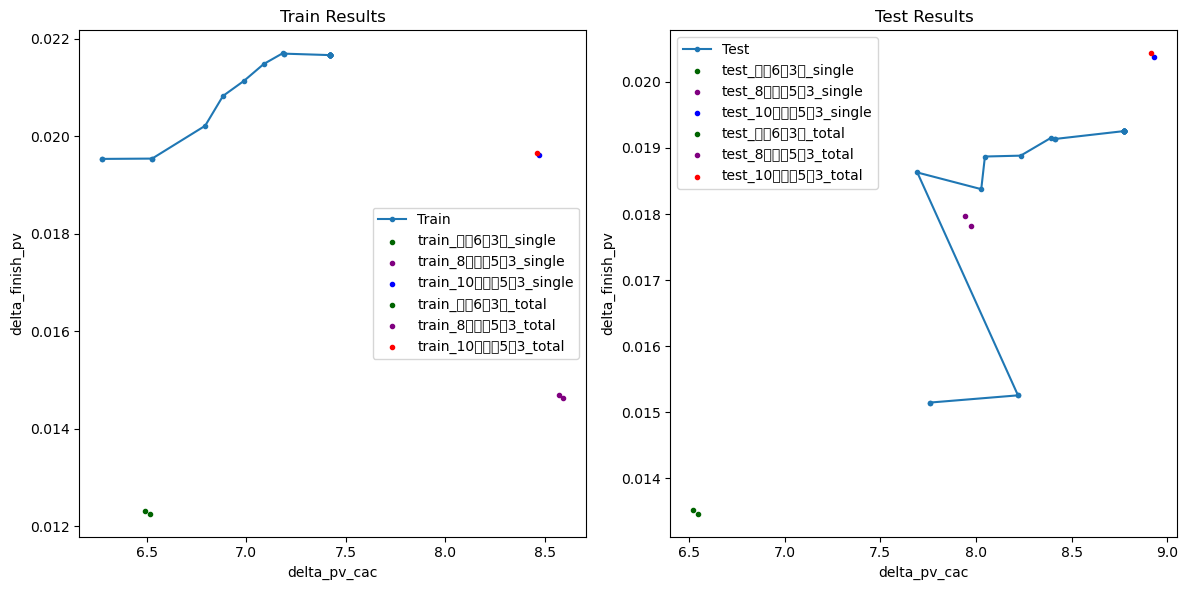

In [47]:
#group_name_list = ['DS空白', '留存6张3元', '8元留存5张3','留存6张5元']
#group_name_list = ['DS空白', '留存6张3元','留存6张5元']
#group_name_list = ['DS空白', '留存6张3元', '10元留存5张3','留存6张5元']
#group_name_list = ['DS空白', '留存6张3元','8元留存5张3']
group_name_list = ['DS空白', '留存6张3元','8元留存5张3','10元留存5张3']
cost_list = np.arange(6.5, 9.0, 0.1)
#discount_para = {'DS空白':0, '留存6张3元':1, '8元留存5张3':2, '留存6张5元':3}
#discount_para = {'DS空白':0, '留存6张3元':1, '留存6张5元':2}
#discount_para = {'DS空白':0, '留存6张3元':1, '8元留存5张3':2}
#discount_para = {'DS空白':0, '留存6张3元':1, '10元留存5张3':2, '留存6张5元':3}
discount_para = {'DS空白':0, '留存6张3元':1, '8元留存5张3':2, '10元留存5张3':3}

# 对应这里的 all_columns和stages使用上 与上方使用的用于分桶的columns保持对应关系，并加上_per， 如: 'probcap8_minus_left65_per'
#all_columns = ['coupon_prob_per', 'left65_minus_left63_per', 'left63_per'] 
#all_columns = ['fin_order_mini_28d', 'coupon_prob_per', 'prob555_minus_left63_per', 'left65_minus_left63_per', 'left63_per']
#all_columns = ['coupon_prob_per', 'left65_per', 'left853_per','left63_per'] 
#all_columns = ['coupon_prob_per', 'left65_per', 'left853_per','left65_minus_left63_per', 'left853_minus_left63','left63_per'] 
#all_columns = ['coupon_prob_per', 'left65_minus_left63_per', 'left853_minus_left63','left853_per','left63_per'] 
#all_columns = ['coupon_prob_per', 'left65_per','left63_per'] 
all_columns = ['cost_1_per', 'left65_per', 'left853_per', 'left63_per', 'left65_minus_left63_per','left853_minus_left63_per'] 
#all_columns = ['cost_1_per', 'left65_minus_left63_per', 'left65_per', 'left63_per'] 
#all_columns = ['coupon_prob_per', 'left65_per','left63_per'] 
"""
stages = [
    (['coupon_prob_per', 'prob555_minus_left63_per', 'left65_minus_left63_per', 'left63_per'], 15000),
    (['prob555_minus_left63_per', 'left65_minus_left63_per'], 15000),
    (['left63_per'], 20000)
]

stages = [
    (['fin_order_mini_28d', 'coupon_prob_per', 'prob555_minus_left63_per', 'left65_minus_left63_per', 'left63_per'], 10000),
    (['fin_order_mini_28d', 'prob555_minus_left63_per', 'left65_minus_left63_per'], 10000),
    (['fin_order_mini_28d', 'left63_per'], 15000)
]
stages = [
    (['coupon_prob_per', 'left65_per', 'left853_per','left63_per'], 10000),
    (['left853_per','left63_per'], 10000),
    (['left63_per'], 20000)
]
stages = [
    (['coupon_prob_per', 'left65_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000),
    (['left65_minus_left63_per', 'left853_minus_left63_per'], 10000),
    (['left63_per'], 20000)
]

stages = [
    (['coupon_prob_per', 'left65_minus_left63_per', 'left853_per', 'left63_per'], 10000),
    (['left65_minus_left63_per', 'left63_per'], 10000),
    (['left65_minus_left63_per', 'left853_per'], 10000),
    (['left853_per', 'left63_per'], 10000),
    (['left63_per'], 20000)
]
stages = [
    (['coupon_prob_per', 'left65_per', 'left853_per','left63_per'], 10000),
    (['left65_per','left853_per'], 15000),
    (['left63_per'], 15000)
]

stages = [
    (['coupon_prob_per', 'left65_per','left63_per'], 10000),
    (['left65_per','left63_per'], 10000),
    (['left63_per'], 10000)
]

stages = [
    (['coupon_prob_per', 'left65_minus_left63_per','left853_per','left63_per'], 10000),
    (['left65_minus_left63_per', 'left853_per'], 10000),
    (['left853_per', 'left63_per'], 10000),
    (['left63_per'], 20000)
]  

stages = [
    (['cost_1_per', 'left65_minus_left63_per','left65_per','left63_per'], 10000),
    (['left65_minus_left63_per','left63_per'], 10000),
    (['left63_per'], 15000)
] # 好1

stages = [
    (['cost_1_per', 'left65_minus_left63_per','left63_per'], 10000),
    (['left65_per','left63_per'], 10000),
    (['left63_per'], 15000)
] #好2
stages = [
    (['coupon_prob_per', 'left65_minus_left63_per','left65_per'], 10000),
    (['left65_per','left63_per'], 10000),
    (['left63_per'], 15000)
] # 好3
stages = [
    (['cost_1_per', 'left65_minus_left63_per','left65_per'], 10000),
    (['left65_minus_left63_per','left63_per'], 10000),
    (['left63_per'], 15000)
]  # 好4

stages = [
    (['coupon_prob_per', 'left65_minus_left63_per','left65_per'], 10000),
    (['left65_minus_left63_per','left63_per'], 10000),
    (['left65_per','left63_per'], 10000),
    (['left63_per'], 15000)
]  # 好5

stages = [
    (['cost_1_per', 'left65_minus_left63_per','left65_per','left63_per'], 10000),
    (['cost_1_per','left65_minus_left63_per','left65_per'], 10000),
    (['left63_per'], 15000)
] # 好1+1

stages = [
    (['cost_1_per', 'left65_minus_left63_per','left63_per'], 10000),
    (['cost_1_per','left65_minus_left63_per','left65_per'], 10000),
    (['left63_per'], 15000)
] # 好1+1+1

stages = [
    (['cost_1_per', 'left65_minus_left63_per','left63_per'], 10000),
    (['cost_1_per','left65_minus_left63_per','left65_per'], 10000),
    (['left65_minus_left63_per','left63_per'], 10000),
    (['left63_per'], 15000)
] # 好1+1+1+1

stages = [
    (['cost_1_per', 'left65_minus_left63_per','left63_per'], 10000),
    (['cost_1_per','left65_minus_left63_per'], 10000),
    (['left63_per'], 15000)
] # 好1+1+1+1+1

stages = [
    (['cost_1_per', 'left65_per','left63_per'], 15000),
    (['cost_1_per','left65_minus_left63_per','left65_per'], 15000),
    (['left65_minus_left63_per','left63_per'], 15000),
    (['left63_per'], 20000)
] # 63,853,1053 混个决策 好1

stages = [
    (['cost_1_per', 'left65_per','left63_per'], 15000),
    (['cost_1_per','left65_minus_left63_per','left65_per'], 15000),
    (['cost_1_per','left63_per'], 15000),
    (['left65_minus_left63_per','left63_per'], 15000),
    (['left63_per'], 20000)
] # 63,853,1053 混个决策 好2

stages = [
    (['cost_1_per', 'left65_per','left63_per'], 15000),
    (['cost_1_per','left65_minus_left63_per','left65_per'], 15000),
    (['left65_per','left63_per'], 15000),
    (['left63_per'], 20000)
] # 63,853,1053 混个决策 好3


stages = [
    (['cost_1_per', 'left65_per','left63_per'], 10000),
    (['cost_1_per','left65_minus_left63_per','left65_per'], 10000),
    (['left65_per','left63_per'], 15000),
    (['left63_per'], 15000)
] # 63,853,1053 混个决策 好4

stages = [
    (['cost_1_per', 'left65_per','left63_per'], 15000),
    (['cost_1_per','left65_minus_left63_per','left65_per'], 15000),
    (['cost_1_per','left63_per'], 15000),
    (['left65_minus_left63_per','left63_per'], 15000),
    (['left63_per'], 20000)
] # 63,853,1053 混个决策 好5

----------------------------------------------------------------------------------------------------
stages = [
    (['cost_1_per', 'left65_minus_left63_per','left853_minus_left63_per','left63_per'], 15000),
    (['cost_1_per','left65_minus_left63_per','left63_per'], 15000),
    (['cost_1_per','left853_per','left63_per'], 15000),
    (['left63_per'], 20000)
] # 63,853,1053 混合决策好6

stages = [
    (['cost_1_per', 'left65_minus_left63_per','left853_minus_left63_per','left63_per'], 15000),
    (['cost_1_per','left65_minus_left63_per','left63_per'], 15000),
    (['cost_1_per','left853_minus_left63_per','left65_per'], 15000),
    (['left63_per'], 20000)
] # 63,853,1053  混合决策好7


stages = [
    (['cost_1_per', 'left65_minus_left63_per','left853_minus_left63_per','left63_per'], 15000),
    (['cost_1_per','left65_minus_left63_per','left63_per'], 15000),
    (['left65_minus_left63_per','left853_minus_left63_per'], 15000),
    (['left63_per'], 20000)
] # 63,853,1053  混合决策好8


stages = [
    (['cost_1_per', 'left65_minus_left63_per','left853_minus_left63_per','left63_per'], 15000),
    (['cost_1_per','left65_minus_left63_per','left63_per'], 15000),
    (['left65_minus_left63_per','left65_per'], 15000),
    (['left63_per'], 20000)
] # 63,853,1053  混合决策好9

stages = [
    (['cost_1_per', 'left65_minus_left63_per','left853_minus_left63_per','left63_per'], 15000),
    (['cost_1_per','left65_minus_left63_per','left63_per'], 15000),
    (['left853_minus_left63_per','left853_per'], 15000),
    (['left63_per'], 20000)
] # 63,853,1053  混合决策好10


stages = [
    (['cost_1_per', 'left65_minus_left63_per','left853_minus_left63_per','left63_per'], 15000),
    (['cost_1_per','left65_minus_left63_per','left63_per'], 15000),
    (['left853_minus_left63_per','left65_per'], 15000),
    (['left63_per'], 20000)
] # 63,853,1053 混合决策好10+1  好一点

stages = [
    (['cost_1_per', 'left65_minus_left63_per','left853_minus_left63_per','left63_per'], 15000),
    (['cost_1_per','left65_minus_left63_per','left63_per'], 15000),
    (['left853_minus_left63_per','left63_per'], 15000),
    (['left63_per'], 20000)
] # 63,853,1053  混合决策好10+2
"""


stages = [
    (['cost_1_per', 'left65_minus_left63_per','left853_minus_left63_per','left63_per'], 15000),
    (['cost_1_per','left65_minus_left63_per','left63_per'], 15000),
    (['left853_minus_left63_per','left63_per'], 15000),
    (['left63_per'], 20000)
] # 63,853,1053

# 使用笛卡尔积
# train_df3, val_df3, bucket_mapping13, reverse_mapping3, processed_data3, next_processed_data3, discount_res_list3, discount_res_test_list3,train_list1, test_list3, tongbu_list3, tongbu_all_list3 = main_try(train_move_bucketing3, val_move_bucketing3, group_name_list, control_name='DS空白',cost_list=cost_list, all_columns=all_columns, stages=stages, discount_para=discount_para, method=0,read_directly=False,show_tongbu=True)

# 不使用笛卡尔积
train_df3, val_df3, bucket_mapping13, reverse_mapping3, processed_data3, next_processed_data3, discount_res_list3, discount_res_test_list3,train_list1, test_list3, tongbu_list3, tongbu_all_list3 = main_try(train_move_bucketing3, val_move_bucketing3, group_name_list, control_name='DS空白',cost_list=cost_list, all_columns=all_columns, stages=stages, discount_para=discount_para, method=0,read_directly=False,show_tongbu=True,combinations=False)

In [35]:
tongbu_list3

[[5.431688499294766,
  0.016672509312608365,
  6.224599691527386,
  0.012392950772856088],
 [7.172825464867085,
  0.021882062877800354,
  8.234279754282818,
  0.015437347832609033],
 [8.56041923027294,
  0.02007098714206719,
  8.473247450661518,
  0.02057237678359115]]

In [48]:
test_array = np.array(test_list3)
pd.DataFrame(test_array,columns=['约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次'])

,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
0,6.5,7.761629,0.015146,0.006170,2.454650
1,6.6,7.761629,0.015146,0.006170,2.454650
2,6.7,8.219628,0.015254,0.006198,2.461233
3,6.8,8.219628,0.015254,0.006198,2.461233
4,6.9,7.693399,0.018629,0.007042,2.645436
5,7.0,8.027505,0.018377,0.007072,2.598602
6,7.1,8.046763,0.018871,0.007150,2.639104
7,7.2,8.233665,0.018884,0.007321,2.579368
8,7.3,8.390504,0.019151,0.007439,2.574551
9,7.4,8.414451,0.019137,0.007417,2.580140


In [18]:
discount_res_list3[14]

{0: '8元留存5张3',
 1: '10元留存5张3',
 2: '10元留存5张3',
 3: '留存6张3元',
 4: '留存6张3元',
 5: '10元留存5张3',
 6: '10元留存5张3',
 7: '10元留存5张3',
 8: '8元留存5张3',
 9: '8元留存5张3',
 10: '留存6张3元',
 11: '10元留存5张3',
 12: '8元留存5张3',
 13: '8元留存5张3',
 14: '10元留存5张3',
 15: '10元留存5张3',
 16: '留存6张3元',
 17: '8元留存5张3',
 18: '10元留存5张3',
 19: '10元留存5张3',
 20: '10元留存5张3',
 21: '10元留存5张3',
 22: '10元留存5张3',
 23: '10元留存5张3',
 24: '留存6张3元',
 25: '10元留存5张3',
 26: '留存6张3元',
 27: '10元留存5张3',
 28: '8元留存5张3',
 29: '8元留存5张3',
 30: '8元留存5张3',
 31: '留存6张3元',
 32: '10元留存5张3',
 33: '10元留存5张3',
 34: '8元留存5张3',
 35: '留存6张3元',
 36: '8元留存5张3',
 37: '留存6张3元',
 38: '10元留存5张3',
 39: '10元留存5张3',
 40: '10元留存5张3',
 41: '留存6张3元',
 42: '8元留存5张3',
 43: '10元留存5张3',
 44: '8元留存5张3',
 45: '10元留存5张3',
 46: '8元留存5张3',
 47: '8元留存5张3',
 -1: '留存6张3元'}

In [136]:
discount_res_test_list3[13]

{-1: '留存6张3元',
 0: '留存6张5元',
 1: 'DS空白',
 2: '留存6张5元',
 3: '留存6张3元',
 4: '留存6张3元',
 5: '留存6张5元',
 6: '留存6张3元',
 7: '留存6张5元',
 8: '留存6张5元',
 9: '留存6张5元',
 10: 'DS空白',
 11: '留存6张5元',
 12: '留存6张3元',
 13: '留存6张5元',
 14: '留存6张5元',
 15: '留存6张5元',
 16: '留存6张3元',
 17: '留存6张3元',
 18: '留存6张3元',
 19: '留存6张5元',
 20: '留存6张5元',
 21: '留存6张5元',
 22: '留存6张5元',
 23: '留存6张3元',
 24: '留存6张5元',
 25: '留存6张3元',
 26: '留存6张5元',
 27: 'DS空白',
 28: '留存6张3元',
 29: '留存6张5元',
 30: '留存6张3元',
 31: '留存6张3元'}

In [109]:
QUERY_ALL_FMT = """
with base as (
    select t1.*
    from
    ( select
        if(flowtree_group_name = 'DS空白', 'DS空白', group_name_eve) as group_name_eve,
        pid, oneid,
        flowtree_group_name,
        send_cnt, send_success_cnt, send_cost, send_remind_cost, outcall_cost, remind_cost, msg_coupon_cost as coupon_cost,outcall_coupon_cost,outcall_coupon2_cost, 
        cast(if(finish_cnt > 0, 1.0, 0.0) as double) as uv_label,
        finish_cnt as pv_label,
        cast(if(finish_cnt_7d > 0, 1.0, 0.0) as double) as uv_label_7d,
        finish_cnt_7d as pv_label_7d,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost, 0.0)+ nvl(outcall_coupon_cost, 0.0)+ nvl(outcall_coupon2_cost, 0.0)) as double) as cost,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double) as cost_7d,
        dt, 
        if(fin_order_mini_28d >= 5, 1, 0.72) as weight, 
        if(fin_order_mini_28d >= 5, 1, 0) as fin_order_mini_28d
    from {traindata_tbname_via_growstrategy}
    where dt in {seed_dts}
    and new_exp = '迭代流量'
    and ((flowtree_group_name = '探索' and group_name_eve in ('8元留存5张3', '留存6张5元', '留存6张3元')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
    )t1
),
prediction_agg as (
    select
        bs.*,
        case when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'DS空白' then 0
             else null
        end as real_treatment,
        nvl(mapping_data.left63, 999) as left63,
        nvl(mapping_data.left65_minus_left63, 999) as left65_minus_left63,
        nvl(mapping_data.left65, 999) as left65,
        nvl(mapping_data.left853_minus_left63, 999) as left853_minus_left63,
        nvl(mapping_data.left853, 999) as left853,
        nvl(mapping_data.cost_1, 999) as cost_1,
        nvl(mapping_data.cost_2, 999) as cost_2,
        nvl(mapping_data.cost_3, 999) as cost_3,
        mapping_data.treatment as model_treatment
    from (
        select * from base
    ) bs
    left join (
        select 
            pid,
            date_add(label_dt, 1) as dt,
            treatment,
            uplift_1 as left63,
            uplift_2 as left853,
            uplift_3 as left65,
            uplift_4 as left853_minus_left63,
            uplift_5 as left65_minus_left63,
            cost_1,
            cost_2,
            cost_3
        from {mapping_data}
        where date_add(label_dt, 1) in {seed_dts}
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)

select *
from prediction_agg
"""

all_rct_data_fmt_1 = QUERY_ALL_FMT.format(
    seed_dts=tuple(dt for dt in CHECK_DTS[1:]),
    dts=tuple(dt for dt in CHECK_DTS[:-1]),
    traindata_tbname_via_growstrategy='dm.ut_alg_flowback_msg_outcall_label_di',
    mapping_data='dm.ut_alg_flowback_outcall_euen_26_v212_month_3_4_model_inference_di'
)
all_rct_data_df_1 = spark.sql(all_rct_data_fmt_1)

v1 = all_rct_data_df_1.toPandas()
v1.head(5)

,group_name_eve,pid,oneid,flowtree_group_name,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_cost,remind_cost,coupon_cost,outcall_coupon_cost,outcall_coupon2_cost,uv_label,pv_label,uv_label_7d,pv_label_7d,cost,cost_7d,dt,weight,fin_order_mini_28d,real_treatment,left63,left65_minus_left63,left65,left853_minus_left63,left853,cost_1,cost_2,cost_3,model_treatment
0,DS空白,1000247463936,v1_17592428685696,DS空白,0.0,0.0,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,2026-05-26,1.00,1,0,0.002606,0.001073,0.003680,-0.000094,0.002513,0.004682,0.014604,0.006374,0.0
1,留存6张3元,100074969,v1_17592563219918,探索,0.0,0.0,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,2026-05-23,1.00,1,1,0.050100,0.026709,0.076808,0.033152,0.083252,0.058716,0.290613,0.196140,1.0
2,留存6张5元,100127411,v1_17592906470481,探索,2.0,1.0,0.021,0.0,0.12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.141,0.141,2026-05-22,1.00,1,3,0.003051,0.000483,0.003534,-0.001033,0.002018,0.005268,0.014372,0.005636,3.0
3,留存6张3元,100231960,v1_17592851449251,探索,0.0,0.0,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,2026-05-24,1.00,1,1,0.010879,0.005793,0.016672,0.004478,0.015356,0.011482,0.025740,0.022624,1.0
4,DS空白,100342750,v1_17593137852407,DS空白,0.0,0.0,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,2026-05-25,1.00,1,0,0.004638,0.002501,0.007139,0.001004,0.005642,0.006349,0.019425,0.009836,0.0


In [110]:
#train_dates = ['2026-04-21']*7
#val_dates = ['2026-03-26','2026-03-27','2026-03-28','2026-03-29','2026-03-30','2026-03-31','2026-04-01']
train_dates = ['2026-05-21']*7
#train_dates = ['2026-05-14','2026-05-15', '2026-05-16', '2026-05-17', '2026-05-18', '2026-05-19', '2026-05-20']
#val_dates = ['2026-05-18','2026-05-19', '2026-05-20','2026-05-21','2026-05-22','2026-05-23', '2026-05-24']
val_dates = ['2026-05-22','2026-05-23', '2026-05-24','2026-05-25','2026-05-26','2026-05-27','2026-05-28']
group_name_list = ['DS空白', '8元留存5张3', '留存6张3元', '留存6张5元']
# 定义需要计算分位数的列和分位数范围
# 比如 多加入 probcap8_minus_left63, 原始列值要在sql中计算好
#columns = ['coupon_prob', 'left65_minus_left63', 'left63']
columns = ['cost_1', 'left65','left853', 'left63','left65_minus_left63','left853_minus_left63']
quantile_thresholds_list1, train_move_bucketing1, val_move_bucketing1 = move_threshold_main(v1, group_name_list, columns, train_dates, val_dates)
#quantile_thresholds_list3, train_move_bucketing3, val_move_bucketing3 = move_threshold_main_customize(v2, group_name_list, columns, train_dates, val_dates,is_customize=True)

['2026-05-15', '2026-05-16', '2026-05-17', '2026-05-18', '2026-05-19', '2026-05-20', '2026-05-21']
['2026-05-22']
['2026-05-15', '2026-05-16', '2026-05-17', '2026-05-18', '2026-05-19', '2026-05-20', '2026-05-21']
['2026-05-23']
['2026-05-15', '2026-05-16', '2026-05-17', '2026-05-18', '2026-05-19', '2026-05-20', '2026-05-21']
['2026-05-24']
['2026-05-15', '2026-05-16', '2026-05-17', '2026-05-18', '2026-05-19', '2026-05-20', '2026-05-21']
['2026-05-25']
['2026-05-15', '2026-05-16', '2026-05-17', '2026-05-18', '2026-05-19', '2026-05-20', '2026-05-21']
['2026-05-26']
['2026-05-15', '2026-05-16', '2026-05-17', '2026-05-18', '2026-05-19', '2026-05-20', '2026-05-21']
['2026-05-27']
['2026-05-15', '2026-05-16', '2026-05-17', '2026-05-18', '2026-05-19', '2026-05-20', '2026-05-21']
['2026-05-28']


In [111]:
quantile_thresholds_list1

[{'cost_1': array([8.14757310e-05, 1.95264248e-03, 3.67276180e-03, 5.41448267e-03,
         7.52915628e-03, 1.15413118e-02, 1.65673792e-02, 2.28590190e-02,
         3.27450402e-02]),
  'left65': array([0.00114662, 0.0034907 , 0.00560314, 0.00783439, 0.0108788 ,
         0.01608039, 0.02264852, 0.03136095, 0.04605181]),
  'left853': array([0.000649  , 0.00268738, 0.00456553, 0.00660655, 0.00934381,
         0.0138934 , 0.01997382, 0.02818379, 0.04431496]),
  'left63': array([0.00117382, 0.00242654, 0.00352818, 0.00469945, 0.00639877,
         0.00986021, 0.01434536, 0.02003979, 0.0303646 ]),
  'left65_minus_left63': array([-8.94669443e-05,  1.03046708e-03,  2.05239523e-03,  3.11271809e-03,
          4.42886166e-03,  6.09082831e-03,  8.33650529e-03,  1.15105569e-02,
          1.60008222e-02]),
  'left853_minus_left63': array([-0.00071691,  0.00012411,  0.00093038,  0.00179422,  0.00280528,
          0.00409237,  0.00584145,  0.00838428,  0.01441487])},
 {'cost_1': array([8.14757310e-05, 

(676252, 38) (655310, 38)
['cost_1_per', 'left65_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 0 ==============================


,cost_1_per,left65_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,40598
111,0.2,0.2,0.2,16441
222,0.3,0.3,0.3,12714
333,0.4,0.4,0.4,12121
444,0.5,0.5,0.5,13910
544,0.6,0.5,0.5,10996
555,0.6,0.6,0.6,15837
655,0.7,0.6,0.6,13394
656,0.7,0.6,0.7,10294
666,0.7,0.7,0.7,16886


['cost_1_per', 'left65_minus_left63_per', 'left65_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left65_minus_left63_per,left65_per,counts
100,0.2,0.1,0.1,11525
211,0.3,0.2,0.2,13324
322,0.4,0.3,0.3,14164
433,0.5,0.4,0.4,14903


['left65_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
4,0.5,22104
5,0.6,19152
6,0.7,24659
7,0.8,23052
8,0.9,20637



============================== Final Small Combinations ==============================
Small Combinations (<15000 samples):


,left63_per,counts
0,0.1,5902
1,0.2,11715
2,0.3,13706
3,0.4,13485
9,1.0,7


[24 10 23 33 38  6 11 17 16  5 29  0 15  8 35 37 27  9 34 36 12  3 14 22
 18  1 28 31 19 26  7 25  4 30  2 32 20 13 21]
rct_pred_data:      bucket_name exp_name  in_uv  finish_uv  finish_pv  total_cost  delta_cvr  \
0              0     DS空白  26087       17.0       70.0       0.000        NaN   
1              0   留存6张3元   9373        8.0       28.0      97.761   0.000304   
2              0   留存6张5元   5138        7.0       23.0      86.907   0.001793   
3              1     DS空白  10544       13.0       70.0       0.000        NaN   
4              1   留存6张3元   3835        5.0       26.0      28.876   0.000141   
..           ...      ...    ...        ...        ...         ...        ...   
112           37   留存6张3元   4809      138.0      331.0     771.759   0.029032   
113           37   留存6张5元   2385       78.0      195.0     975.767   0.041963   
114           38     DS空白  28905      300.0      883.0       0.000        NaN   
115           38   留存6张3元  10419      103.0      309.0 

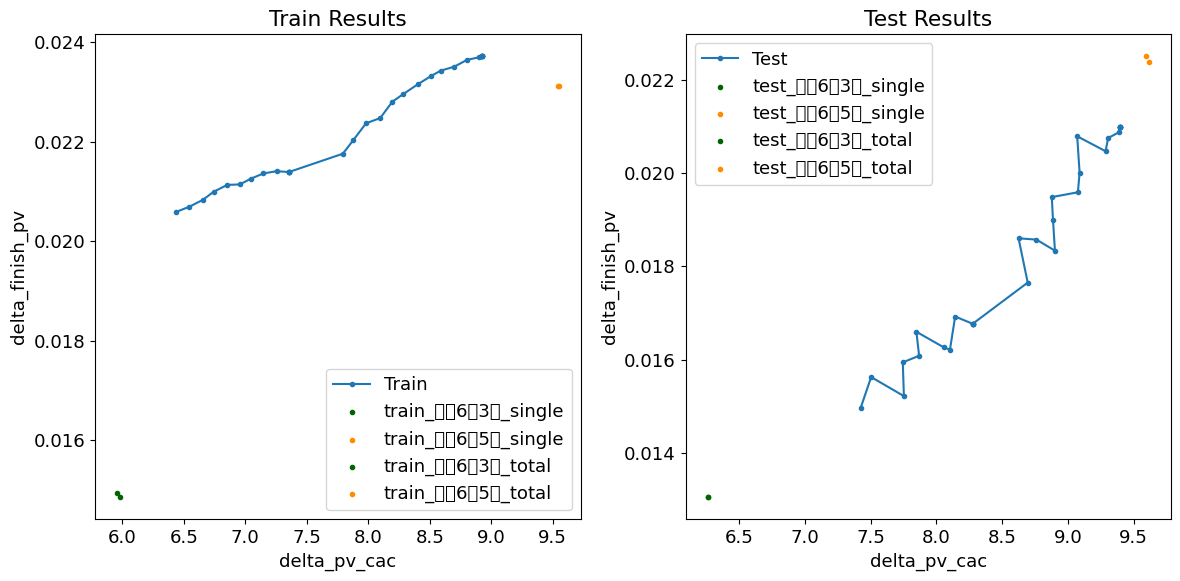

In [130]:
#group_name_list = ['DS空白', '留存6张3元', '8元留存5张3','留存6张5元']
group_name_list = ['DS空白', '留存6张3元','留存6张5元']
cost_list = np.arange(6.5, 9.5, 0.1)
#discount_para = {'DS空白':0, '留存6张3元':1, '8元留存5张3':2, '留存6张5元':3}
discount_para = {'DS空白':0, '留存6张3元':1, '留存6张5元':2}

# 对应这里的 all_columns和stages使用上 与上方使用的用于分桶的columns保持对应关系，并加上_per， 如: 'probcap8_minus_left65_per'
#all_columns = ['coupon_prob_per', 'left65_minus_left63_per', 'left63_per'] 
#all_columns = ['fin_order_mini_28d', 'coupon_prob_per', 'prob555_minus_left63_per', 'left65_minus_left63_per', 'left63_per']
#all_columns = ['coupon_prob_per', 'left65_per', 'left853_per','left63_per'] 
#all_columns = ['coupon_prob_per', 'left65_per', 'left853_per','left65_minus_left63_per', 'left853_minus_left63','left63_per'] 
#all_columns = ['coupon_prob_per', 'left65_minus_left63_per', 'left853_minus_left63','left853_per','left63_per'] 
#all_columns = ['coupon_prob_per', 'left65_per','left63_per'] 
#all_columns = ['coupon_prob_per', 'left65_per', 'left853_per','left65_minus_left63_per','left63_per'] 
all_columns = ['cost_1_per', 'left65_minus_left63_per', 'left65_per', 'left63_per'] 
#all_columns = ['coupon_prob_per', 'left65_per','left63_per'] 
"""
stages = [
    (['coupon_prob_per', 'prob555_minus_left63_per', 'left65_minus_left63_per', 'left63_per'], 15000),
    (['prob555_minus_left63_per', 'left65_minus_left63_per'], 15000),
    (['left63_per'], 20000)
]

stages = [
    (['fin_order_mini_28d', 'coupon_prob_per', 'prob555_minus_left63_per', 'left65_minus_left63_per', 'left63_per'], 10000),
    (['fin_order_mini_28d', 'prob555_minus_left63_per', 'left65_minus_left63_per'], 10000),
    (['fin_order_mini_28d', 'left63_per'], 15000)
]
stages = [
    (['coupon_prob_per', 'left65_per', 'left853_per','left63_per'], 10000),
    (['left853_per','left63_per'], 10000),
    (['left63_per'], 20000)
]
stages = [
    (['coupon_prob_per', 'left65_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000),
    (['left65_minus_left63_per', 'left853_minus_left63_per'], 10000),
    (['left63_per'], 20000)
]

stages = [
    (['coupon_prob_per', 'left65_minus_left63_per', 'left853_per', 'left63_per'], 10000),
    (['left65_minus_left63_per', 'left63_per'], 10000),
    (['left65_minus_left63_per', 'left853_per'], 10000),
    (['left853_per', 'left63_per'], 10000),
    (['left63_per'], 20000)
]
stages = [
    (['coupon_prob_per', 'left65_per', 'left853_per','left63_per'], 10000),
    (['left65_per','left853_per'], 15000),
    (['left63_per'], 15000)
]

stages = [
    (['coupon_prob_per', 'left65_per','left63_per'], 10000),
    (['left65_per','left63_per'], 10000),
    (['left63_per'], 10000)
]

stages = [
    (['coupon_prob_per', 'left65_minus_left63_per','left853_per','left63_per'], 10000),
    (['left65_minus_left63_per', 'left853_per'], 10000),
    (['left853_per', 'left63_per'], 10000),
    (['left63_per'], 20000)
]  

stages = [
    (['cost_1_per', 'left65_minus_left63_per','left65_per','left63_per'], 10000),
    (['left65_minus_left63_per','left63_per'], 10000),
    (['left63_per'], 15000)
] # 好1

stages = [
    (['cost_1_per', 'left65_minus_left63_per','left63_per'], 10000),
    (['left65_per','left63_per'], 10000),
    (['left63_per'], 15000)
] #好2
stages = [
    (['coupon_prob_per', 'left65_minus_left63_per','left65_per'], 10000),
    (['left65_per','left63_per'], 10000),
    (['left63_per'], 15000)
] # 好3
stages = [
    (['cost_1_per', 'left65_minus_left63_per','left65_per'], 10000),
    (['left65_minus_left63_per','left63_per'], 10000),
    (['left63_per'], 15000)
]  # 好4

stages = [
    (['coupon_prob_per', 'left65_minus_left63_per','left65_per'], 10000),
    (['left65_minus_left63_per','left63_per'], 10000),
    (['left65_per','left63_per'], 10000),
    (['left63_per'], 15000)
]  # 好5

stages = [
    (['cost_1_per', 'left65_minus_left63_per','left65_per','left63_per'], 10000),
    (['cost_1_per','left65_minus_left63_per','left65_per'], 10000),
    (['left63_per'], 15000)
] # 好1+1

stages = [
    (['cost_1_per', 'left65_minus_left63_per','left63_per'], 10000),
    (['cost_1_per','left65_minus_left63_per','left65_per'], 10000),
    (['left63_per'], 15000)
] # 好1+1+1

stages = [
    (['cost_1_per', 'left65_minus_left63_per','left63_per'], 10000),
    (['cost_1_per','left65_minus_left63_per','left65_per'], 10000),
    (['left65_minus_left63_per','left63_per'], 10000),
    (['left63_per'], 15000)
] # 好1+1+1+1

stages = [
    (['cost_1_per', 'left65_minus_left63_per','left63_per'], 10000),
    (['cost_1_per','left65_minus_left63_per'], 10000),
    (['left63_per'], 15000)
] # 好1+1+1+1+1
"""
stages = [
    (['cost_1_per', 'left65_minus_left63_per','left63_per'], 10000),
    (['cost_1_per','left65_minus_left63_per','left65_per'], 10000),
    (['left65_minus_left63_per','left63_per'], 10000),
    (['left63_per'], 15000)
] # 好1+1+1+1


# 使用笛卡尔积
# train_df3, val_df3, bucket_mapping13, reverse_mapping3, processed_data3, next_processed_data3, discount_res_list3, discount_res_test_list3,train_list1, test_list3, tongbu_list3, tongbu_all_list3 = main_try(train_move_bucketing3, val_move_bucketing3, group_name_list, control_name='DS空白',cost_list=cost_list, all_columns=all_columns, stages=stages, discount_para=discount_para, method=0,read_directly=False,show_tongbu=True)

# 不使用笛卡尔积
train_df1, val_df1, bucket_mapping1, reverse_mapping1, processed_data1, next_processed_data1, discount_res_list1, discount_res_test_list1,train_list1, test_list1, tongbu_list1, tongbu_all_list1 = main_try(train_move_bucketing1, val_move_bucketing1, group_name_list, control_name='DS空白',cost_list=cost_list, all_columns=all_columns, stages=stages, discount_para=discount_para, method=0,read_directly=False,show_tongbu=True,combinations=False)


In [126]:
test_array = np.array(test_list1)
pd.DataFrame(test_array,columns=['约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次'])

,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
0,6.5,7.322822,0.015705,0.006336,2.478810
1,6.6,7.309120,0.016313,0.006647,2.454216
2,6.7,7.412801,0.016584,0.006702,2.474635
3,6.8,7.545344,0.016554,0.006910,2.395683
4,6.9,7.651328,0.016962,0.007089,2.392887
5,7.0,7.783148,0.016798,0.007057,2.380435
6,7.1,7.672515,0.017459,0.007028,2.484138
7,7.2,7.755009,0.017934,0.007204,2.489537
8,7.3,7.880072,0.017772,0.007173,2.477502
9,7.4,7.899227,0.017869,0.007208,2.479032


In [ ]:
discount_res_test_list1[15]